## Project Objectives: OpenFlights Bipartite Network Analysis

**Main Objective**

My goal is to analyze the OpenFlights airline–airport network to understand connectivity patterns, identify important airlines and airports, and discover how groups of airlines and airports are connected through their route relationships.

**Specific Objectives**

- **Data Preparation:** Clean and integrate the OpenFlights airlines, airports, and routes datasets to create a reliable dataset for network analysis.

- **Bipartite Network Construction:** Build a bipartite network where airlines and airports represent two types of nodes, and edges represent their relationships.

- **Degree Centrality Analysis:** Identify airlines connected to the most airports and airports served by the most airlines to understand their importance within the network.

- **Edge Weight Analysis:** Calculate the number of distinct recorded routes associated with each airline–airport relationship to identify relationships with greater route diversity.

- **Exploratory Data Analysis:** Examine degree and edge weight distributions using descriptive statistics and visualizations to identify connectivity patterns and differences across the network.

- **Island Method:** Apply different edge weight thresholds to identify which airlines and airports remain connected as lower-weight relationships are removed, and examine how the network separates into distinct groups.

- **Island Characteristics Analysis:** Investigate the airlines and airports within the major islands, compare their connectivity patterns, and explore what distinguishes one group from another.

- **Data Visualization and Interpretation:** Use network visualizations, charts, and summary statistics to communicate findings and explain the structure of the airline network.

**Expected Outcome**

Through this project, I aim to identify highly connected airlines and airport hubs, understand how route diversity is distributed, and discover meaningful groups within the airline network. My analysis will demonstrate data cleaning, data transformation, exploratory data analysis, network analysis, visualization, and data-driven interpretation skills.

# Airlines Dataset (airlines.dat)

Purpose: This file is my directory of airline companies.

Key Information: It records the official name of the carrier, their home country, active status, and industry codes (IATA/ICAO).

Network Role (Group 1 Nodes): In my bimodal graph, these represent my first distinct group.

Columns:

Airline ID: The unique numerical identifier for the airline.

Name: The corporate name of the airline.

Alias: Alternative names (often \N for none).

IATA / ICAO: Standard 2-letter and 3-letter industry codes.

Callsign: The identifier pilots use over the radio.

Country: The country where the airline is headquartered.

Active: "Y" if the airline is operating, "N" if defunct.

# Airports Dataset (airports.dat)

Purpose: This file lists the physical airports worldwide.

Key Information: It includes the airport's name, city, country, IATA code, and geographic coordinates.

Network Role (Group 2 Nodes): In my bimodal graph, these represent my second distinct group.

Columns:

Airport ID: The unique numerical identifier for the airport.

Name / City / Country: The name and location of the airport.

IATA / ICAO: Standard 3-letter and 4-letter industry codes.

#  Routes Dataset (routes.dat)

Purpose: This file is my master schedule mapping the flight paths.

Key Information: Every row represents a commercial flight path, detailing the airline, departure airport, arrival airport, and aircraft type.

Network Role (The Edges): This dataset provides the connections between my two groups by matching an Airline ID to a Source Airport ID.

Columns:

Airline / Airline ID: The carrier code and unique ID.

Source Airport / Source Airport ID: The departure airport code and unique ID.

Destination Airport / Destination Airport ID: The arrival airport code and unique ID.

Codeshare: "Y" if operated by a partner airline, empty otherwise.

Stops: Number of layovers.

Equipment: 3-letter code for the plane type.

In [160]:
import pandas as pd

# Define the raw GitHub URLs for the OpenFlights data
routes_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/routes.dat"
airports_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat"
airlines_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/airlines.dat"

# The original .dat files do not contain column headers, so we assign them manually
# based on the OpenFlights documentation so the data makes sense when you read it.

routes_cols = ['Airline', 'Airline ID', 'Source Airport', 'Source Airport ID',
               'Destination Airport', 'Destination Airport ID', 'Codeshare', 'Stops', 'Equipment']
routes_df = pd.read_csv(routes_url, header=None, names=routes_cols)

airports_cols = ['Airport ID', 'Name', 'City', 'Country', 'IATA', 'ICAO',
                 'Latitude', 'Longitude', 'Altitude', 'Timezone', 'DST', 'Tz_database', 'Type', 'Source']
airports_df = pd.read_csv(airports_url, header=None, names=airports_cols)

airlines_cols = ['Airline ID', 'Name', 'Alias', 'IATA', 'ICAO', 'Callsign', 'Country', 'Active']
airlines_df = pd.read_csv(airlines_url, header=None, names=airlines_cols)

# Display the first 3 rows of each dataset to understand the structure
print("=== ROUTES DATA ===")
display(routes_df.head(3))

print("\n=== AIRPORTS DATA ===")
display(airports_df.head(3))

print("\n=== AIRLINES DATA ===")
display(airlines_df.head(3))

=== ROUTES DATA ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Codeshare,Stops,Equipment
0,2B,410,AER,2965,KZN,2990,NaN,0,CR2
1,2B,410,ASF,2966,KZN,2990,NaN,0,CR2
2,2B,410,ASF,2966,MRV,2962,NaN,0,CR2



=== AIRPORTS DATA ===


,Airport ID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,Tz_database,Type,Source
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.08169,145.391998,5282,10,U,Pacific/Port_Moresby,airport,OurAirports
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.20708,145.789001,20,10,U,Pacific/Port_Moresby,airport,OurAirports
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.82679,144.296005,5388,10,U,Pacific/Port_Moresby,airport,OurAirports



=== AIRLINES DATA ===


,Airline ID,Name,Alias,IATA,ICAO,Callsign,Country,Active
0,-1,Unknown,\N,-,NaN,\N,\N,Y
1,1,Private flight,\N,-,NaN,NaN,NaN,Y
2,2,135 Airways,\N,NaN,GNL,GENERAL,United States,N


# Description of the Datasets

Before building our bipartite network, we need to understand:
- How many airline records are available?
- How many airport records are available?
- How many routes are recorded?
- Are there missing values that could affect our network analysis?



Objective: I will examine the size and structure of the OpenFlights datasets.



Methodology: I will identify missing values, duplicate records, and potential data-quality issues before constructing the bipartite network.



Analysis: I will investigate relationships between airlines and airports using route data.



Interpretation: My findings will help me understand the connectivity patterns between the two distinct groups.



Conclusion: I will summarize the network structure, apply the island method, and evaluate the characteristics of each group.

# Exploratory Data Analysis:

I examined three OpenFlights datasets to understand their size and data quality.

- **Routes:** 67,663 records describing airline routes between airports.

- **Airports:** 7,698 records containing airport information, including location and geographic coordinates.

- **Airlines:** 6,162 records containing airline information, including company name, country, and operating status.

**Missing Values:**

- The Routes dataset contains 53,066 missing Codeshare values and 18 missing Equipment values.
- The Airports dataset contains 49 missing City values.
- The Airlines dataset contains missing values in several descriptive fields, including IATA, Callsign, Alias, and Country.

**Key Finding:**

I determined that the datasets are sufficiently large for my bipartite network analysis. I will focus on airline IDs and airport IDs because these identifiers are essential for establishing relationships between the two groups.

I will also examine missing identifiers represented by `\N`, which may not appear in the initial missing-value counts.

# Select Relevant Columns from Each Dataset
Objective
I will select only the columns needed to construct my airline–airport bipartite network and analyze the characteristics of each group.

In [161]:
# Select relevant fields from the Airlines dataset
airlines_selected = airlines_df[
    ['Airline ID',
     'Name',
     'IATA',
     'ICAO',
     'Country',
     'Active']
].copy()

# Select relevant fields from the Airports dataset
airports_selected = airports_df[
    ['Airport ID',
     'Name',
     'City',
     'Country',
     'IATA',
     'ICAO',
     'Latitude',
     'Longitude']
].copy()

# Select relevant fields from the Routes dataset
routes_selected = routes_df[
    ['Airline',
     'Airline ID',
     'Source Airport',
     'Source Airport ID',
     'Destination Airport',
     'Destination Airport ID']
].copy()

# Display selected datasets
print("=== SELECTED AIRLINES DATA ===")
display(airlines_selected.head())

print("\n=== SELECTED AIRPORTS DATA ===")
display(airports_selected.head())

print("\n=== SELECTED ROUTES DATA ===")
display(routes_selected.head())

# Check dataset dimensions
print("\n=== SELECTED DATASET DIMENSIONS ===")
print("Airlines:", airlines_selected.shape)
print("Airports:", airports_selected.shape)
print("Routes:", routes_selected.shape)

=== SELECTED AIRLINES DATA ===


,Airline ID,Name,IATA,ICAO,Country,Active
0,-1,Unknown,-,NaN,\N,Y
1,1,Private flight,-,NaN,NaN,Y
2,2,135 Airways,NaN,GNL,United States,N
3,3,1Time Airline,1T,RNX,South Africa,Y
4,4,2 Sqn No 1 Elementary Flying Training School,NaN,WYT,United Kingdom,N



=== SELECTED AIRPORTS DATA ===


,Airport ID,Name,City,Country,IATA,ICAO,Latitude,Longitude
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001



=== SELECTED ROUTES DATA ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078



=== SELECTED DATASET DIMENSIONS ===
Airlines: (6162, 6)
Airports: (7698, 8)
Routes: (67663, 6)


# Data Type and Missing Value Validation

I examined the data types and missing values in my three selected OpenFlights datasets.

I evaluated both standard null values (NaN) and the `\N` placeholders used by OpenFlights to represent missing information.

I also reviewed the expected data types for each column. Airline and airport identifiers should be numeric, geographic coordinates should be numeric, and descriptive attributes should be stored as strings.

This validation will help me identify data-quality issues before cleaning and merging the datasets to construct my bipartite network.

In [162]:
# Define selected datasets
datasets = {
    "Airlines": airlines_selected,
    "Airports": airports_selected,
    "Routes": routes_selected
}

# Examine data types and missing values
for name, df in datasets.items():

    print(f"\n=== {name.upper()} DATASET ===")

    # Identify missing values represented by \N
    missing_placeholder = (
        df.astype("string").eq(r"\N").fillna(False)
    )

    # Create summary table
    summary = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Null (NaN)": df.isna().sum(),
        "Missing (\\N)": missing_placeholder.sum(),
        "Total Missing": (
            df.isna() | missing_placeholder
        ).sum()
    })

    display(summary)


=== AIRLINES DATASET ===


,Data Type,Null (NaN),Missing (\N),Total Missing
Airline ID,int64,0,0,0
Name,object,0,0,0
IATA,object,4627,1,4628
ICAO,object,87,188,275
Country,object,15,3,18
Active,object,0,0,0



=== AIRPORTS DATASET ===


,Data Type,Null (NaN),Missing (\N),Total Missing
Airport ID,int64,0,0,0
Name,object,0,0,0
City,object,49,0,49
Country,object,0,0,0
IATA,object,0,1626,1626
ICAO,object,0,1,1
Latitude,float64,0,0,0
Longitude,float64,0,0,0



=== ROUTES DATASET ===


,Data Type,Null (NaN),Missing (\N),Total Missing
Airline,object,0,0,0
Airline ID,object,0,479,479
Source Airport,object,0,0,0
Source Airport ID,object,0,220,220
Destination Airport,object,0,0,0
Destination Airport ID,object,0,221,221


Investigating missing records

In [163]:
# Filter routes with missing Airline IDs (\N)
missing_airline_ids = routes_selected[
    routes_selected['Airline ID'] == r'\N'
]

# Display records
print("Total records with missing Airline IDs:", len(missing_airline_ids))

display(missing_airline_ids)

Total records with missing Airline IDs: 479


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
312,3H,\N,AKV,5506,YIK,5504
313,3H,\N,AKV,5506,YPX,6727
314,3H,\N,XGR,5512,YVP,154
315,3H,\N,YGL,62,YGW,5496
316,3H,\N,YGL,62,YPX,6727
...,...,...,...,...,...,...
66596,ZD,\N,DZA,915,MJN,929
66597,ZD,\N,DZA,915,NOS,930
66598,ZD,\N,HAH,912,DZA,915
66599,ZD,\N,MJN,929,DZA,915


In [164]:
# Display first 20 rows of Airlines dataset
print("=== AIRLINES DATASET ===")
display(airlines_selected.head(5))

# Display first 20 rows of Airports dataset
print("\n=== AIRPORTS DATASET ===")
display(airports_selected.head(5))

# Display first 20 rows of Routes dataset
print("\n=== ROUTES DATASET ===")
display(routes_selected.head(5))

=== AIRLINES DATASET ===


,Airline ID,Name,IATA,ICAO,Country,Active
0,-1,Unknown,-,NaN,\N,Y
1,1,Private flight,-,NaN,NaN,Y
2,2,135 Airways,NaN,GNL,United States,N
3,3,1Time Airline,1T,RNX,South Africa,Y
4,4,2 Sqn No 1 Elementary Flying Training School,NaN,WYT,United Kingdom,N



=== AIRPORTS DATASET ===


,Airport ID,Name,City,Country,IATA,ICAO,Latitude,Longitude
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001



=== ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


In [165]:
# Display original route records with missing Airline IDs
missing_airlines = routes_df[
    routes_df['Airline ID'] == r'\N'
]

# Examine airline codes associated with missing IDs
display(
    missing_airlines[
    ['Airline',
     'Airline ID',
     'Source Airport',
     'Source Airport ID',
     'Destination Airport',
     'Destination Airport ID']
    ].head(20)
)

,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
312,3H,\N,AKV,5506,YIK,5504
313,3H,\N,AKV,5506,YPX,6727
314,3H,\N,XGR,5512,YVP,154
315,3H,\N,YGL,62,YGW,5496
316,3H,\N,YGL,62,YPX,6727
317,3H,\N,YGL,62,YUL,146
318,3H,\N,YGW,5496,YGL,62
319,3H,\N,YGW,5496,YPH,5520
320,3H,\N,YGW,5496,YSK,5529
321,3H,\N,YGW,5496,YUD,5515


I will display the first 20 rows with missing Airport IDs, separately for the Source Airport ID and Destination Airport ID columns in my Routes dataset.

In [166]:
# First 20 rows with missing Source Airport IDs
print("=== MISSING SOURCE AIRPORT IDs ===")

missing_source = routes_selected[
    routes_selected['Source Airport ID'] == r'\N'
]

display(missing_source.head(20))


# First 20 rows with missing Destination Airport IDs
print("\n=== MISSING DESTINATION AIRPORT IDs ===")

missing_destination = routes_selected[
    routes_selected['Destination Airport ID'] == r'\N'
]

display(missing_destination.head(20))

=== MISSING SOURCE AIRPORT IDs ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
38,2B,410,TGK,\N,DME,4029
54,2G,1654,KCK,\N,IKT,2937
1163,4O,17885,PQM,\N,MEX,1824
2113,5Z,18946,PBZ,\N,CPT,797
2114,5Z,18946,PBZ,\N,JNB,813
2249,6E,2850,HYD,\N,AMD,2994
2250,6E,2850,HYD,\N,BBI,3042
2251,6E,2850,HYD,\N,BLR,3131
2252,6E,2850,HYD,\N,BOM,2997
2253,6E,2850,HYD,\N,CCU,3043



=== MISSING DESTINATION AIRPORT IDs ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
7,2B,410,DME,4029,TGK,\N
48,2G,1654,IKT,2937,KCK,\N
1136,4O,17885,MEX,1824,PQM,\N
2108,5Z,18946,CPT,797,PBZ,\N
2120,6E,2850,AMD,2994,HYD,\N
2128,6E,2850,BBI,3042,HYD,\N
2142,6E,2850,BLR,3131,HYD,\N
2161,6E,2850,BOM,2997,HYD,\N
2181,6E,2850,CCU,3043,HYD,\N
2199,6E,2850,COK,3136,HYD,\N


In [167]:
# Find routes with missing Source Airport IDs
missing_source = routes_df[
    routes_df['Source Airport ID'] == r'\N'
]

# Display the first 20 records
print("Total Missing Source Airport IDs:", len(missing_source))

display(
    missing_source[
        ['Airline', 'Source Airport', 'Source Airport ID']
    ].head(5)
)

Total Missing Source Airport IDs: 220


,Airline,Source Airport,Source Airport ID
38,2B,TGK,\N
54,2G,KCK,\N
1163,4O,PQM,\N
2113,5Z,PBZ,\N
2114,5Z,PBZ,\N


In [168]:
# Find airport TGK and display all columns
tgk_airport = airports_df[
    airports_df['IATA'] == 'TGK'
]

display(tgk_airport)

,Airport ID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,Tz_database,Type,Source
5254,6932,Taganrog Yuzhny Airport,Taganrog,Russia,TGK,URRT,47.198333,38.849167,117,3,N,Europe/Moscow,airport,OurAirports


In [169]:
# Filter routes for airline code 3H
routes_3H = routes_selected[
    routes_selected['Airline'] == '3H'
]

# Display total records
print("Total routes for airline 3H:", len(routes_3H))

# Display all matching records
display(routes_3H)

Total routes for airline 3H: 64


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
312,3H,\N,AKV,5506,YIK,5504
313,3H,\N,AKV,5506,YPX,6727
314,3H,\N,XGR,5512,YVP,154
315,3H,\N,YGL,62,YGW,5496
316,3H,\N,YGL,62,YPX,6727
...,...,...,...,...,...,...
371,3H,\N,YWK,161,YZV,202
372,3H,\N,YZG,5535,YIK,5504
373,3H,\N,YZG,5535,YWB,7253
374,3H,\N,YZV,202,YKL,80


# Data Quality Issues Identified in the OpenFlights Routes Dataset (routes_selected)

I identified three data-quality issues in my Routes dataset (routes_selected):

479 missing Airline IDs: I will investigate whether these identifiers can be recovered by matching the Airline column in routes_selected with the IATA column in the Airlines dataset (airlines_selected).

220 missing Source Airport IDs: I will investigate whether these identifiers can be recovered by matching the Source Airport column in routes_selected with the IATA column in the Airports dataset (airports_selected).

221 missing Destination Airport IDs: I will investigate whether these identifiers can be recovered by matching the Destination Airport column in routes_selected with the IATA column in the Airports dataset (airports_selected).

These three identifiers are essential for constructing my airline–airport bipartite network.

I will investigate each issue separately and attempt to recover missing identifiers using the corresponding reference datasets. I will preserve my original datasets during the cleaning process and exclude records with unresolved identifiers only when preparing my final network.

In [170]:
# Step 1: Identify records with missing Airline IDs
missing_airlines = routes_selected[
    routes_selected['Airline ID'] == r'\N'
].copy()

# Step 2: Match airline codes with the Airlines dataset
airline_matches = missing_airlines.merge(
    airlines_selected[
        ['Airline ID', 'Name', 'IATA', 'ICAO']
    ],
    left_on='Airline',
    right_on='IATA',
    how='left',
    suffixes=('_Routes', '_Airlines')
)

# Step 3: Display the results
print("=== AIRLINE ID RECOVERY INVESTIGATION ===")

display(
    airline_matches[
        ['Airline', 'Airline ID_Routes',
         'Airline ID_Airlines', 'Name', 'IATA', 'ICAO']
    ].head(20)
)

=== AIRLINE ID RECOVERY INVESTIGATION ===


,Airline,Airline ID_Routes,Airline ID_Airlines,Name,IATA,ICAO
0,3H,\N,NaN,NaN,NaN,NaN
1,3H,\N,NaN,NaN,NaN,NaN
2,3H,\N,NaN,NaN,NaN,NaN
3,3H,\N,NaN,NaN,NaN,NaN
4,3H,\N,NaN,NaN,NaN,NaN
5,3H,\N,NaN,NaN,NaN,NaN
6,3H,\N,NaN,NaN,NaN,NaN
7,3H,\N,NaN,NaN,NaN,NaN
8,3H,\N,NaN,NaN,NaN,NaN
9,3H,\N,NaN,NaN,NaN,NaN


Results of Missing Airline ID Investigation

I identified 479 records with missing Airline IDs in my Routes dataset (routes_selected).

To recover these identifiers, I matched the Airline column in the Routes dataset with the IATA column in the Airlines dataset (airlines_selected).

My investigation found that none of the 479 records had a matching Airline ID in the Airlines reference dataset.

Therefore, I could not recover these identifiers using IATA-based matching.

I will preserve these records during data preparation. However, I may need to exclude records with unresolved Airline IDs when constructing my final bipartite network, because I need reliable airline identifiers to establish connections between airlines and airports.

In [171]:
# Count recovered and unrecovered Airline IDs
print("=== AIRLINE ID MATCHING SUMMARY ===")

print("Total missing Airline ID records:",
      len(missing_airlines))

print("Records with matching Airline IDs:",
      airline_matches['Airline ID_Airlines'].notna().sum())

print("Records without matching Airline IDs:",
      airline_matches['Airline ID_Airlines'].isna().sum())

=== AIRLINE ID MATCHING SUMMARY ===
Total missing Airline ID records: 479
Records with matching Airline IDs: 0
Records without matching Airline IDs: 479


Investigate Missing Source Airport IDs
I have completed my investigation of the 479 missing Airline IDs. Now I will investigate the 220 missing Source Airport IDs in my Routes dataset (routes_selected).
My Objective
I want to determine whether I can recover missing Source Airport IDs by matching two columns

In [172]:
# Step 1: Identify routes with missing Source Airport IDs
missing_source = routes_selected[
    routes_selected['Source Airport ID'] == r'\N'
].copy()

# Step 2: Match Source Airport codes with Airport IATA codes
source_matches = missing_source.merge(
    airports_selected[
        ['Airport ID', 'Name', 'City', 'Country', 'IATA']
    ],
    left_on='Source Airport',
    right_on='IATA',
    how='left'
)

# Step 3: Display matching results
print("=== SOURCE AIRPORT ID RECOVERY INVESTIGATION ===")

display(
    source_matches[
        ['Source Airport', 'Source Airport ID',
         'Airport ID', 'Name', 'City', 'Country']
    ].head(20)
)

=== SOURCE AIRPORT ID RECOVERY INVESTIGATION ===


,Source Airport,Source Airport ID,Airport ID,Name,City,Country
0,TGK,\N,6932.0,Taganrog Yuzhny Airport,Taganrog,Russia
1,KCK,\N,6922.0,Kirensk Airport,Kirensk,Russia
2,PQM,\N,13334.0,Palenque International Airport,Palenque,Mexico
3,PBZ,\N,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
4,PBZ,\N,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
5,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
6,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
7,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
8,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
9,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India


In [173]:
# Count how many airport records use each IATA code
iata_counts = (
    airports_selected[
        airports_selected['IATA'] != r'\N'
    ]
    .groupby('IATA')['Airport ID']
    .nunique()
)

# Check how many airports match each missing source code
source_check = missing_source.copy()

source_check['Number of Matches'] = (
    source_check['Source Airport']
    .map(iata_counts)
    .fillna(0)
    .astype(int)
)

# Summarize the results
print("=== SOURCE AIRPORT MATCH SUMMARY ===")

print("Total missing Source Airport IDs:",
      len(source_check))

print("Records with one unique airport match:",
      (source_check['Number of Matches'] == 1).sum())

print("Records with no airport match:",
      (source_check['Number of Matches'] == 0).sum())

print("Records with multiple airport matches:",
      (source_check['Number of Matches'] > 1).sum())

=== SOURCE AIRPORT MATCH SUMMARY ===
Total missing Source Airport IDs: 220
Records with one unique airport match: 156
Records with no airport match: 64
Records with multiple airport matches: 0


Merging my Routes dataset (routes_selected) with my Airports dataset (airports_selected) to recover the missing Source Airport ID values.
I am matching:
routes_selected['Source Airport'] = airports_selected['IATA']

In [174]:
# Identify routes with missing Source Airport IDs
missing_source = routes_selected[
    routes_selected['Source Airport ID'] == r'\N'
].copy()

# Merge with Airports dataset using IATA codes
source_matches = missing_source.merge(
    airports_selected[
        ['Airport ID', 'Name', 'City', 'Country', 'IATA']
    ],
    left_on='Source Airport',
    right_on='IATA',
    how='left'
)

# Display the first 20 records
print("=== SOURCE AIRPORT MATCHING RESULTS ===")

display(
    source_matches[
        ['Source Airport', 'Source Airport ID',
         'IATA', 'Airport ID', 'Name', 'City', 'Country']
    ].head(20)
)

=== SOURCE AIRPORT MATCHING RESULTS ===


,Source Airport,Source Airport ID,IATA,Airport ID,Name,City,Country
0,TGK,\N,TGK,6932.0,Taganrog Yuzhny Airport,Taganrog,Russia
1,KCK,\N,KCK,6922.0,Kirensk Airport,Kirensk,Russia
2,PQM,\N,PQM,13334.0,Palenque International Airport,Palenque,Mexico
3,PBZ,\N,PBZ,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
4,PBZ,\N,PBZ,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
5,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
6,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
7,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
8,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
9,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India


Fill Missing Source Airport IDs
I will now use the matching information to fill the existing Source Airport ID column in routes_working.

In [175]:
# Create a working copy of the Routes dataset
routes_working = routes_selected.copy()

# Create an airport lookup with unique IATA codes
airport_lookup = (
    airports_selected[
        airports_selected['IATA'].isin(
            iata_counts[iata_counts == 1].index
        )
    ]
    .drop_duplicates(subset='IATA')
    .set_index('IATA')['Airport ID']
)

# Identify missing Source Airport IDs
missing_mask = (
    routes_working['Source Airport ID'] == r'\N'
)

# Fill missing Source Airport IDs using matching IATA codes
routes_working.loc[missing_mask, 'Source Airport ID'] = (
    routes_working.loc[missing_mask, 'Source Airport']
    .map(airport_lookup)
    .fillna(r'\N')
)

# Verify the results
print("=== SOURCE AIRPORT ID CLEANING RESULTS ===")

print("Recovered IDs:",
      220 - (routes_working['Source Airport ID'] == r'\N').sum())

print("Remaining missing IDs:",
      (routes_working['Source Airport ID'] == r'\N').sum())

print("Total records:", len(routes_working))

=== SOURCE AIRPORT ID CLEANING RESULTS ===
Recovered IDs: 156
Remaining missing IDs: 64
Total records: 67663


In [176]:
display(routes_working.head(20))

,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078
5,2B,410,DME,4029,KZN,2990
6,2B,410,DME,4029,NBC,6969
7,2B,410,DME,4029,TGK,\N
8,2B,410,DME,4029,UUA,6160
9,2B,410,EGO,6156,KGD,2952


Follow the same steps to recover the 221 missing Destination Airport IDs.
The main difference is that I will now match:

routes_working['Destination Airport'] = airports_selected['IATA']

I will continue using routes_working so that I preserve the 156 Source Airport IDs I already recovered.

Investigate Missing Destination Airport IDs

In [177]:
# Identify routes with missing Destination Airport IDs
missing_destination = routes_working[
    routes_working['Destination Airport ID'] == r'\N'
].copy()

# Match Destination Airport codes with Airport IATA codes
destination_matches = missing_destination.merge(
    airports_selected[
        ['Airport ID', 'Name', 'City', 'Country', 'IATA']
    ],
    left_on='Destination Airport',
    right_on='IATA',
    how='left'
)

# Display matching results
print("=== DESTINATION AIRPORT ID RECOVERY INVESTIGATION ===")

display(
    destination_matches[
        ['Destination Airport', 'Destination Airport ID',
         'IATA', 'Airport ID', 'Name', 'City', 'Country']
    ].head(20)
)

=== DESTINATION AIRPORT ID RECOVERY INVESTIGATION ===


,Destination Airport,Destination Airport ID,IATA,Airport ID,Name,City,Country
0,TGK,\N,TGK,6932.0,Taganrog Yuzhny Airport,Taganrog,Russia
1,KCK,\N,KCK,6922.0,Kirensk Airport,Kirensk,Russia
2,PQM,\N,PQM,13334.0,Palenque International Airport,Palenque,Mexico
3,PBZ,\N,PBZ,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
4,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
5,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
6,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
7,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
8,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
9,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India


Count Unique and Unmatched Destination Airport IDs
I will use the same approach I used for Source Airport IDs.

My investigation shows that 152 of the 221 missing Destination Airport IDs can potentially be recovered using the Airports dataset (airports_selected).

In [178]:
# Count how many unique airports use each IATA code
iata_counts = (
    airports_selected[
        airports_selected['IATA'] != r'\N'
    ]
    .groupby('IATA')['Airport ID']
    .nunique()
)

# Check how many airports match each missing destination code
destination_check = missing_destination.copy()

destination_check['Number of Matches'] = (
    destination_check['Destination Airport']
    .map(iata_counts)
    .fillna(0)
    .astype(int)
)

# Summarize the results
print("=== DESTINATION AIRPORT MATCH SUMMARY ===")

print("Total missing Destination Airport IDs:",
      len(destination_check))

print("Records with one unique airport match:",
      (destination_check['Number of Matches'] == 1).sum())

print("Records with no airport match:",
      (destination_check['Number of Matches'] == 0).sum())

print("Records with multiple airport matches:",
      (destination_check['Number of Matches'] > 1).sum())

=== DESTINATION AIRPORT MATCH SUMMARY ===
Total missing Destination Airport IDs: 221
Records with one unique airport match: 152
Records with no airport match: 69
Records with multiple airport matches: 0


Recover the 152 Destination Airport IDs
I will update the existing Destination Airport ID column in routes_working.

In [179]:
# Create a lookup using unique airport IATA codes
valid_codes = iata_counts[iata_counts == 1].index

airport_lookup = (
    airports_selected[
        airports_selected['IATA'].isin(valid_codes)
    ]
    .drop_duplicates(subset='IATA')
    .set_index('IATA')['Airport ID']
)

# Identify missing Destination Airport IDs
missing_mask = (
    routes_working['Destination Airport ID'] == r'\N'
)

# Recover missing Destination Airport IDs
routes_working.loc[missing_mask, 'Destination Airport ID'] = (
    routes_working.loc[missing_mask, 'Destination Airport']
    .map(airport_lookup)
    .fillna(r'\N')
)

# Verify results
print("=== DESTINATION AIRPORT ID CLEANING RESULTS ===")

print(
    "Recovered Destination Airport IDs:",
    221 - (routes_working['Destination Airport ID'] == r'\N').sum()
)

print(
    "Remaining missing Destination Airport IDs:",
    (routes_working['Destination Airport ID'] == r'\N').sum()
)

print("Total route records:", len(routes_working))

=== DESTINATION AIRPORT ID CLEANING RESULTS ===
Recovered Destination Airport IDs: 152
Remaining missing Destination Airport IDs: 69
Total route records: 67663


In [180]:
# Display the first 50 records of my cleaned Routes dataset
print("=== CLEANED ROUTES DATASET ===")

display(routes_working.head(5))

# Display dataset dimensions
print("Total rows:", routes_working.shape[0])
print("Total columns:", routes_working.shape[1])

=== CLEANED ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Total rows: 67663
Total columns: 6


In [181]:
# Identify the three ID columns
id_columns = [
    'Airline ID',
    'Source Airport ID',
    'Destination Airport ID'
]

# Count remaining missing identifiers
missing_summary = (
    routes_working[id_columns]
    .astype('string')
    .eq(r'\N')
    .sum()
    .to_frame('Remaining Missing IDs')
)

print("=== FINAL ROUTES MISSING ID SUMMARY ===")
display(missing_summary)

print("Total route records:", len(routes_working))

=== FINAL ROUTES MISSING ID SUMMARY ===


,Remaining Missing IDs
Airline ID,479
Source Airport ID,64
Destination Airport ID,69


Total route records: 67663


In [182]:
# Identify missing IDs in my working Routes dataset
missing_ids = (
    routes_working[
        ['Airline ID', 'Source Airport ID', 'Destination Airport ID']
    ]
    .astype('string')
    .eq(r'\N')
    .fillna(True)
)

# Count route records with missing identifiers
print("=== ROUTE RECORD QUALITY SUMMARY ===")

print("Total route records:", len(routes_working))

print(
    "Routes with at least one missing ID:",
    missing_ids.any(axis=1).sum()
)

print(
    "Routes with all three IDs available:",
    (~missing_ids.any(axis=1)).sum()
)

=== ROUTE RECORD QUALITY SUMMARY ===
Total route records: 67663
Routes with at least one missing ID: 599
Routes with all three IDs available: 67064


Create a Complete Routes Dataset
I will create a separate DataFrame called routes_complete without changing routes_working.

### Final Routes Data Preparation

After investigating and recovering missing identifiers, I found that 67,064 of the original 67,663 route records contained all three required identifiers.

The remaining 599 records had at least one unresolved identifier. I created a separate dataset, `routes_complete`, containing records with complete Airline IDs, Source Airport IDs, and Destination Airport IDs.

I retained all 67,663 records in `routes_working` to preserve my cleaned data. I will use `routes_complete` as the starting point for constructing my airline–airport bipartite network.

In [183]:
# Select the identifier columns
id_columns = [
    'Airline ID',
    'Source Airport ID',
    'Destination Airport ID'
]

# Identify records with all three IDs available
complete_mask = (
    routes_working[id_columns]
    .astype('string')
    .ne(r'\N')
    .fillna(False)
    .all(axis=1)
)

# Create a dataset containing complete routes
routes_complete = routes_working.loc[complete_mask].copy()

# Verify the result
print("=== COMPLETE ROUTES DATASET ===")
print("Total complete routes:", len(routes_complete))
print("Dataset shape:", routes_complete.shape)

display(routes_complete.head(5))

=== COMPLETE ROUTES DATASET ===
Total complete routes: 67064
Dataset shape: (67064, 6)


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Validate Airline and Airport IDs
Before constructing my bipartite network, I need to confirm that the IDs in routes_complete actually exist in the corresponding reference tables.
I will start with Airline ID validation only.


Routes with unmatched Airline IDs: 0
My results confirm that all 67,064 route records have valid Airline IDs in the Airlines reference dataset (airlines_selected).

In [184]:
# Convert Airline IDs to numeric values for comparison
route_airline_ids = pd.to_numeric(
    routes_complete['Airline ID'],
    errors='coerce'
)

# Check whether Airline IDs exist in the Airlines dataset
airline_valid = route_airline_ids.isin(
    airlines_selected['Airline ID']
)

print("=== AIRLINE ID VALIDATION ===")

print("Total complete route records:", len(routes_complete))

print("Routes with valid Airline IDs:", airline_valid.sum())

print("Routes with unmatched Airline IDs:", (~airline_valid).sum())

=== AIRLINE ID VALIDATION ===
Total complete route records: 67064
Routes with valid Airline IDs: 67064
Routes with unmatched Airline IDs: 0


Validate Source Airport IDs
Now I will verify that every Source Airport ID in routes_complete exists in the Airports reference dataset (airports_selected).

I am comparing:
routes_complete['Source Airport ID'] = airports_selected['Airport ID']

My results show that 249 route records have Source Airport IDs that do not exist in my Airports reference dataset (airports_selected).

In [185]:
# Convert Source Airport IDs to numeric values
route_source_ids = pd.to_numeric(
    routes_complete['Source Airport ID'],
    errors='coerce'
)

# Check whether Source Airport IDs exist in Airports dataset
source_valid = route_source_ids.isin(
    airports_selected['Airport ID']
)

print("=== SOURCE AIRPORT ID VALIDATION ===")

print("Total complete route records:", len(routes_complete))

print("Routes with valid Source Airport IDs:", source_valid.sum())

print("Routes with unmatched Source Airport IDs:", (~source_valid).sum())

=== SOURCE AIRPORT ID VALIDATION ===
Total complete route records: 67064
Routes with valid Source Airport IDs: 66815
Routes with unmatched Source Airport IDs: 249


Examine the 249 Unmatched Source Airport IDs

In [186]:
# Identify routes with unmatched Source Airport IDs
unmatched_source = routes_complete.loc[
    ~source_valid
].copy()

print("=== UNMATCHED SOURCE AIRPORT RECORDS ===")

print("Total unmatched route records:", len(unmatched_source))

print(
    "Unique unmatched Source Airport IDs:",
    unmatched_source['Source Airport ID'].nunique()
)

# Display the first 20 records
display(
    unmatched_source[
        ['Airline', 'Airline ID',
         'Source Airport', 'Source Airport ID',
         'Destination Airport', 'Destination Airport ID']
    ].head(20)
)

=== UNMATCHED SOURCE AIRPORT RECORDS ===
Total unmatched route records: 249
Unique unmatched Source Airport IDs: 101


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
175,2O,146,AOS,7167,KZB,7176
176,2O,146,KKB,7168,SYB,7173
178,2O,146,KOZ,7164,ORI,7165
179,2O,146,SYB,7173,KPR,7172
270,3F,16262,CGA,7144,HYL,7145
271,3F,16262,CGA,7144,KTN,3808
272,3F,16262,HYL,7145,CGA,7144
273,3F,16262,HYL,7145,KTB,7147
274,3F,16262,HYL,7145,KTN,3808
275,3F,16262,KTB,7147,HYL,7145


Check IATA Matches for the 249 Records
I will compare:
unmatched_source['Source Airport'] = airports_selected['IATA']

In [187]:
# Count unique Airport IDs for each IATA code
iata_counts = (
    airports_selected[
        airports_selected['IATA'] != r'\N'
    ]
    .groupby('IATA')['Airport ID']
    .nunique()
)

# Check for matching airport codes
unmatched_source['IATA Match Count'] = (
    unmatched_source['Source Airport']
    .map(iata_counts)
    .fillna(0)
    .astype(int)
)

print("=== UNMATCHED SOURCE ID INVESTIGATION ===")

print("Total unmatched route records:", len(unmatched_source))

print(
    "Records with one unique IATA match:",
    (unmatched_source['IATA Match Count'] == 1).sum()
)

print(
    "Records with no IATA match:",
    (unmatched_source['IATA Match Count'] == 0).sum()
)

print(
    "Records with multiple IATA matches:",
    (unmatched_source['IATA Match Count'] > 1).sum()
)

=== UNMATCHED SOURCE ID INVESTIGATION ===
Total unmatched route records: 249
Records with one unique IATA match: 9
Records with no IATA match: 240
Records with multiple IATA matches: 0


Examine the 9 Potential Matches
Before replacing any IDs, I want to see the existing Source Airport ID alongside the matching Airport ID.

In [188]:
# Select the 9 records with one unique IATA match
source_candidates = unmatched_source[
    unmatched_source['IATA Match Count'] == 1
].copy()

# Match with the Airports reference dataset
source_candidates = source_candidates.merge(
    airports_selected[
        ['Airport ID', 'IATA', 'Name', 'City', 'Country']
    ],
    left_on='Source Airport',
    right_on='IATA',
    how='left'
)

# Display the potential corrections
print("=== SOURCE AIRPORT ID CORRECTION CANDIDATES ===")

display(
    source_candidates[
        ['Source Airport', 'Source Airport ID',
         'Airport ID', 'Name', 'City', 'Country']
    ]
)

=== SOURCE AIRPORT ID CORRECTION CANDIDATES ===


,Source Airport,Source Airport ID,Airport ID,Name,City,Country
0,JGS,6428,6964,Jinggangshan Airport,Jian,China
1,JGS,6428,6964,Jinggangshan Airport,Jian,China
2,JGS,6428,6964,Jinggangshan Airport,Jian,China
3,JGS,6428,6964,Jinggangshan Airport,Jian,China
4,JGS,6428,6964,Jinggangshan Airport,Jian,China
5,JGS,6428,6964,Jinggangshan Airport,Jian,China
6,JGS,6428,6964,Jinggangshan Airport,Jian,China
7,JGS,6428,6964,Jinggangshan Airport,Jian,China
8,JGS,6428,6964,Jinggangshan Airport,Jian,China


Correct the 9 Source Airport IDs
I will update routes_complete, replacing Source Airport ID 6428 with 6964 only where the Source Airport code is JGS.

In [189]:
# Identify the 9 JGS records with the unmatched Airport ID
jgs_mask = (
    (routes_complete['Source Airport'] == 'JGS') &
    (pd.to_numeric(
        routes_complete['Source Airport ID'],
        errors='coerce'
    ) == 6428)
)

# Count records before correction
print("Records requiring correction:", jgs_mask.sum())

# Correct the Source Airport ID
routes_complete.loc[jgs_mask, 'Source Airport ID'] = 6964

# Verify the correction
print("\n=== CORRECTED JGS RECORDS ===")

display(
    routes_complete.loc[
        routes_complete['Source Airport'] == 'JGS',
        ['Source Airport', 'Source Airport ID']
    ].head(20)
)

Records requiring correction: 9

=== CORRECTED JGS RECORDS ===


,Source Airport,Source Airport ID
16467,JGS,6964
18649,JGS,6964
23987,JGS,6964
23988,JGS,6964
25615,JGS,6964
41685,JGS,6964
41686,JGS,6964
41687,JGS,6964
66922,JGS,6964


In [190]:
# Display my complete Routes dataset
print("=== UPDATED COMPLETE ROUTES DATASET ===")

display(routes_complete.head(5))

# Display dataset dimensions
print("Total rows:", routes_complete.shape[0])
print("Total columns:", routes_complete.shape[1])

=== UPDATED COMPLETE ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Total rows: 67064
Total columns: 6


Validate Destination Airport IDs
I will compare:
routes_complete['Destination Airport ID'] = airports_selected['Airport ID']

In [191]:
# Convert Destination Airport IDs to numeric values
route_destination_ids = pd.to_numeric(
    routes_complete['Destination Airport ID'],
    errors='coerce'
)

# Check whether Destination Airport IDs exist in Airports dataset
destination_valid = route_destination_ids.isin(
    airports_selected['Airport ID']
)

print("=== DESTINATION AIRPORT ID VALIDATION ===")

print("Total complete route records:", len(routes_complete))

print("Routes with valid Destination Airport IDs:",
      destination_valid.sum())

print("Routes with unmatched Destination Airport IDs:",
      (~destination_valid).sum())

=== DESTINATION AIRPORT ID VALIDATION ===
Total complete route records: 67064
Routes with valid Destination Airport IDs: 66810
Routes with unmatched Destination Airport IDs: 254


Investigate the 254 Unmatched Destination Airport IDs
I will follow the same process I used for Source Airport IDs.

In [192]:
# Identify routes with unmatched Destination Airport IDs
unmatched_destination = routes_complete.loc[
    ~destination_valid
].copy()

# Count unique Airport IDs for each IATA code
iata_counts = (
    airports_selected[
        airports_selected['IATA'] != r'\N'
    ]
    .groupby('IATA')['Airport ID']
    .nunique()
)

# Check for matching Destination Airport codes
unmatched_destination['IATA Match Count'] = (
    unmatched_destination['Destination Airport']
    .map(iata_counts)
    .fillna(0)
    .astype(int)
)

# Display investigation results
print("=== UNMATCHED DESTINATION ID INVESTIGATION ===")

print("Total unmatched route records:", len(unmatched_destination))

print(
    "Unique unmatched Destination Airport IDs:",
    unmatched_destination['Destination Airport ID'].nunique()
)

print(
    "Records with one unique IATA match:",
    (unmatched_destination['IATA Match Count'] == 1).sum()
)

print(
    "Records with no IATA match:",
    (unmatched_destination['IATA Match Count'] == 0).sum()
)

print(
    "Records with multiple IATA matches:",
    (unmatched_destination['IATA Match Count'] > 1).sum()
)

=== UNMATCHED DESTINATION ID INVESTIGATION ===
Total unmatched route records: 254
Unique unmatched Destination Airport IDs: 104
Records with one unique IATA match: 9
Records with no IATA match: 245
Records with multiple IATA matches: 0


Examine the 9 Destination Airport ID Candidates

My results show that all 9 unmatched Destination Airport records refer to the same airport: Jinggangshan Airport (JGS), China.
This is the same ID inconsistency I identified and corrected earlier for Source Airport IDs.

In [193]:
# Select records with one unique IATA match
destination_candidates = unmatched_destination[
    unmatched_destination['IATA Match Count'] == 1
].copy()

# Merge with the Airports reference dataset
destination_candidates = destination_candidates.merge(
    airports_selected[
        ['Airport ID', 'IATA', 'Name', 'City', 'Country']
    ],
    left_on='Destination Airport',
    right_on='IATA',
    how='left'
)

# Display potential corrections
print("=== DESTINATION AIRPORT ID CORRECTION CANDIDATES ===")

display(
    destination_candidates[
        ['Destination Airport', 'Destination Airport ID',
         'Airport ID', 'Name', 'City', 'Country']
    ]
)

=== DESTINATION AIRPORT ID CORRECTION CANDIDATES ===


,Destination Airport,Destination Airport ID,Airport ID,Name,City,Country
0,JGS,6428,6964,Jinggangshan Airport,Jian,China
1,JGS,6428,6964,Jinggangshan Airport,Jian,China
2,JGS,6428,6964,Jinggangshan Airport,Jian,China
3,JGS,6428,6964,Jinggangshan Airport,Jian,China
4,JGS,6428,6964,Jinggangshan Airport,Jian,China
5,JGS,6428,6964,Jinggangshan Airport,Jian,China
6,JGS,6428,6964,Jinggangshan Airport,Jian,China
7,JGS,6428,6964,Jinggangshan Airport,Jian,China
8,JGS,6428,6964,Jinggangshan Airport,Jian,China


Correct Destination Airport IDs

In [194]:
# Identify JGS destination records with the unmatched ID
jgs_destination_mask = (
    (routes_complete['Destination Airport'] == 'JGS') &
    (pd.to_numeric(
        routes_complete['Destination Airport ID'],
        errors='coerce'
    ) == 6428)
)

# Count records requiring correction
print("Records requiring correction:",
      jgs_destination_mask.sum())

# Replace the incorrect ID with the matching Airport ID
routes_complete.loc[
    jgs_destination_mask, 'Destination Airport ID'
] = 6964

# Verify the correction
print("\n=== CORRECTED DESTINATION AIRPORT RECORDS ===")

display(
    routes_complete.loc[
        jgs_destination_mask,
        ['Destination Airport', 'Destination Airport ID']
    ]
)

Records requiring correction: 9

=== CORRECTED DESTINATION AIRPORT RECORDS ===


,Destination Airport,Destination Airport ID
16735,JGS,6964
18143,JGS,6964
23963,JGS,6964
24026,JGS,6964
25694,JGS,6964
42215,JGS,6964
42302,JGS,6964
42512,JGS,6964
67096,JGS,6964


In [195]:
# Display my updated Routes dataset
print("=== FINAL COMPLETE ROUTES DATASET ===")

display(routes_complete.head(5))

# Display total rows and columns
print("Total rows:", routes_complete.shape[0])
print("Total columns:", routes_complete.shape[1])

=== FINAL COMPLETE ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Total rows: 67064
Total columns: 6


Final Airport ID Validation

In [196]:
# Validate Source Airport IDs
source_valid = pd.to_numeric(
    routes_complete['Source Airport ID'],
    errors='coerce'
).isin(airports_selected['Airport ID'])

# Validate Destination Airport IDs
destination_valid = pd.to_numeric(
    routes_complete['Destination Airport ID'],
    errors='coerce'
).isin(airports_selected['Airport ID'])

print("=== FINAL AIRPORT ID VALIDATION ===")
print("Unmatched Source Airport IDs:", (~source_valid).sum())
print("Unmatched Destination Airport IDs:", (~destination_valid).sum())

print(
    "Routes with both airport IDs validated:",
    (source_valid & destination_valid).sum()
)

=== FINAL AIRPORT ID VALIDATION ===
Unmatched Source Airport IDs: 240
Unmatched Destination Airport IDs: 245
Routes with both airport IDs validated: 66633


Create My Validated Routes Dataset

In [197]:
# Validate Airline IDs
airline_valid = pd.to_numeric(
    routes_complete['Airline ID'],
    errors='coerce'
).isin(airlines_selected['Airline ID'])

# Validate Source Airport IDs
source_valid = pd.to_numeric(
    routes_complete['Source Airport ID'],
    errors='coerce'
).isin(airports_selected['Airport ID'])

# Validate Destination Airport IDs
destination_valid = pd.to_numeric(
    routes_complete['Destination Airport ID'],
    errors='coerce'
).isin(airports_selected['Airport ID'])

# Create a new dataset with all three IDs validated
routes_validated = routes_complete.loc[
    airline_valid & source_valid & destination_valid
].copy()

# Display results
print("=== VALIDATED ROUTES DATASET ===")
print("Total rows:", routes_validated.shape[0])
print("Total columns:", routes_validated.shape[1])

display(routes_validated.head(20))

=== VALIDATED ROUTES DATASET ===
Total rows: 66633
Total columns: 6


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078
5,2B,410,DME,4029,KZN,2990
6,2B,410,DME,4029,NBC,6969
7,2B,410,DME,4029,TGK,6932.0
8,2B,410,DME,4029,UUA,6160
9,2B,410,EGO,6156,KGD,2952


Conclusion

After cleaning and validating my OpenFlights Routes dataset (routes_selected), I retained 66,633 records (98.48%) out of the original 67,663 records.

I used the Airlines dataset (airlines_selected) to validate Airline IDs and the Airports dataset (airports_selected) to recover and validate Source and Destination Airport IDs.

I excluded 1,030 records (1.52%) due to missing or unmatched identifiers. I preserved all 67,663 records in my cleaned working dataset (routes_working) and created a separate final dataset (routes_validated) containing 66,633 records.

I will use routes_validated to construct my airline–airport bipartite network, ensuring that all airline and airport identifiers exist in their corresponding reference datasets.

In [198]:
# Display the final validated Routes dataset
print("=== FINAL VALIDATED ROUTES DATASET ===")

display(routes_validated.head(5))

print("Total rows:", routes_validated.shape[0])
print("Total columns:", routes_validated.shape[1])

=== FINAL VALIDATED ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Total rows: 66633
Total columns: 6


Merge Airline Information into My Routes Dataset
Which Field Am I Merging On:
routes_validated['Airline ID'] = airlines_selected['Airline ID']

In [199]:
# Create a copy of my validated Routes dataset
routes_enriched = routes_validated.copy()

# Convert Airline IDs to numeric values
routes_enriched['Airline ID'] = pd.to_numeric(
    routes_enriched['Airline ID']
)

# Merge airline information into the Routes dataset
routes_enriched = routes_enriched.merge(
    airlines_selected[
        ['Airline ID', 'Name', 'Country']
    ],
    on='Airline ID',
    how='left',
    validate='many_to_one'
)

# Rename columns for clarity
routes_enriched = routes_enriched.rename(columns={
    'Name': 'Airline Name',
    'Country': 'Airline Country'
})

# Display results
print("=== ROUTES WITH AIRLINE INFORMATION ===")

display(routes_enriched.head(5))

print("Total rows:", routes_enriched.shape[0])
print("Total columns:", routes_enriched.shape[1])

=== ROUTES WITH AIRLINE INFORMATION ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Airline Name,Airline Country
0,2B,410,AER,2965,KZN,2990,Aerocondor,Portugal
1,2B,410,ASF,2966,KZN,2990,Aerocondor,Portugal
2,2B,410,ASF,2966,MRV,2962,Aerocondor,Portugal
3,2B,410,CEK,2968,KZN,2990,Aerocondor,Portugal
4,2B,410,CEK,2968,OVB,4078,Aerocondor,Portugal


Total rows: 66633
Total columns: 8


In [200]:
# Display the first 20 records
print("=== ROUTES WITH AIRLINE INFORMATION ===")

display(routes_enriched.head(5))

# Display dataset dimensions
print("Total rows:", routes_enriched.shape[0])
print("Total columns:", routes_enriched.shape[1])

=== ROUTES WITH AIRLINE INFORMATION ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Airline Name,Airline Country
0,2B,410,AER,2965,KZN,2990,Aerocondor,Portugal
1,2B,410,ASF,2966,KZN,2990,Aerocondor,Portugal
2,2B,410,ASF,2966,MRV,2962,Aerocondor,Portugal
3,2B,410,CEK,2968,KZN,2990,Aerocondor,Portugal
4,2B,410,CEK,2968,OVB,4078,Aerocondor,Portugal


Total rows: 66633
Total columns: 8


In [201]:
import pandas as pd

# Create a copy of my enriched routes dataset
routes_final = routes_enriched.copy()

# Prepare airport reference data
airport_info = airports_selected[
    ['Airport ID', 'Name', 'City', 'Country',
     'Latitude', 'Longitude']
].copy()

# Convert airport IDs to numeric values
routes_final['Source Airport ID'] = pd.to_numeric(
    routes_final['Source Airport ID']
)

routes_final['Destination Airport ID'] = pd.to_numeric(
    routes_final['Destination Airport ID']
)

# STEP A: Merge Source Airport information
source_info = airport_info.rename(columns={
    'Airport ID': 'Source Airport ID',
    'Name': 'Source Airport Name',
    'City': 'Source City',
    'Country': 'Source Country',
    'Latitude': 'Source Latitude',
    'Longitude': 'Source Longitude'
})

routes_final = routes_final.merge(
    source_info,
    on='Source Airport ID',
    how='left',
    validate='many_to_one'
)

# STEP B: Merge Destination Airport information
destination_info = airport_info.rename(columns={
    'Airport ID': 'Destination Airport ID',
    'Name': 'Destination Airport Name',
    'City': 'Destination City',
    'Country': 'Destination Country',
    'Latitude': 'Destination Latitude',
    'Longitude': 'Destination Longitude'
})

routes_final = routes_final.merge(
    destination_info,
    on='Destination Airport ID',
    how='left',
    validate='many_to_one'
)

# Display my final merged dataset
print("=== FINAL MERGED OPENFLIGHTS DATASET ===")

display(routes_final.head(5))

print("Total rows:", routes_final.shape[0])
print("Total columns:", routes_final.shape[1])

=== FINAL MERGED OPENFLIGHTS DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Airline Name,Airline Country,Source Airport Name,Source City,Source Country,Source Latitude,Source Longitude,Destination Airport Name,Destination City,Destination Country,Destination Latitude,Destination Longitude
0,2B,410,AER,2965.0,KZN,2990.0,Aerocondor,Portugal,Sochi International Airport,Sochi,Russia,43.449902,39.956600,Kazan International Airport,Kazan,Russia,55.606201,49.278702
1,2B,410,ASF,2966.0,KZN,2990.0,Aerocondor,Portugal,Astrakhan Airport,Astrakhan,Russia,46.283298,48.006302,Kazan International Airport,Kazan,Russia,55.606201,49.278702
2,2B,410,ASF,2966.0,MRV,2962.0,Aerocondor,Portugal,Astrakhan Airport,Astrakhan,Russia,46.283298,48.006302,Mineralnyye Vody Airport,Mineralnye Vody,Russia,44.225101,43.081902
3,2B,410,CEK,2968.0,KZN,2990.0,Aerocondor,Portugal,Chelyabinsk Balandino Airport,Chelyabinsk,Russia,55.305801,61.503300,Kazan International Airport,Kazan,Russia,55.606201,49.278702
4,2B,410,CEK,2968.0,OVB,4078.0,Aerocondor,Portugal,Chelyabinsk Balandino Airport,Chelyabinsk,Russia,55.305801,61.503300,Tolmachevo Airport,Novosibirsk,Russia,55.012600,82.650703


Total rows: 66633
Total columns: 18


My final dataset is routes_final.
It contains the validated routes merged with airline, source airport, and destination airport information.

In [202]:
# Display my final OpenFlights dataset
print("=== MY FINAL OPENFLIGHTS DATASET ===")

display(routes_final.head(5))

print("Total rows:", routes_final.shape[0])
print("Total columns:", routes_final.shape[1])

=== MY FINAL OPENFLIGHTS DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Airline Name,Airline Country,Source Airport Name,Source City,Source Country,Source Latitude,Source Longitude,Destination Airport Name,Destination City,Destination Country,Destination Latitude,Destination Longitude
0,2B,410,AER,2965.0,KZN,2990.0,Aerocondor,Portugal,Sochi International Airport,Sochi,Russia,43.449902,39.956600,Kazan International Airport,Kazan,Russia,55.606201,49.278702
1,2B,410,ASF,2966.0,KZN,2990.0,Aerocondor,Portugal,Astrakhan Airport,Astrakhan,Russia,46.283298,48.006302,Kazan International Airport,Kazan,Russia,55.606201,49.278702
2,2B,410,ASF,2966.0,MRV,2962.0,Aerocondor,Portugal,Astrakhan Airport,Astrakhan,Russia,46.283298,48.006302,Mineralnyye Vody Airport,Mineralnye Vody,Russia,44.225101,43.081902
3,2B,410,CEK,2968.0,KZN,2990.0,Aerocondor,Portugal,Chelyabinsk Balandino Airport,Chelyabinsk,Russia,55.305801,61.503300,Kazan International Airport,Kazan,Russia,55.606201,49.278702
4,2B,410,CEK,2968.0,OVB,4078.0,Aerocondor,Portugal,Chelyabinsk Balandino Airport,Chelyabinsk,Russia,55.305801,61.503300,Tolmachevo Airport,Novosibirsk,Russia,55.012600,82.650703


Total rows: 66633
Total columns: 18


# Identify the Two Groups in My Bipartite Network
My network will have two groups:
- Group 1: Airlines — Each airline is a node.
- Group 2: Airports — Each airport is a node.
An edge connects an airline to an airport when the airline operates a route involving that airport.
For example, if Airline A operates a route from JFK to LAX, my network will contain two connections:
- Airline A → JFK
- Airline A → LAX
Airports will not connect directly to other airports in this bipartite network.

Count My Network Nodes
Before constructing the network, I will identify how many unique airlines and airports exist in my final dataset.

# Interpretation for the Project:
I identified 546 unique airlines and 3,188 unique airports in my final OpenFlights dataset (routes_final).

Together, these represent 3,734 nodes in my bipartite network.

Airports account for approximately 85.4% of the nodes, while airlines account for 14.6%. This shows that the airport group is substantially larger than the airline group.

In [203]:
import pandas as pd
import networkx as nx

# Count unique airlines
unique_airlines = routes_final['Airline ID'].nunique()

# Combine source and destination airport IDs
all_airports = pd.concat([
    routes_final['Source Airport ID'],
    routes_final['Destination Airport ID']
])

# Count unique airports
unique_airports = all_airports.nunique()

# Calculate total nodes
total_nodes = unique_airlines + unique_airports

# Display results
print("=== MY BIPARTITE NETWORK SUMMARY ===")

print("Unique Airlines:", unique_airlines)
print("Unique Airports:", unique_airports)
print("Total Nodes:", total_nodes)

=== MY BIPARTITE NETWORK SUMMARY ===
Unique Airlines: 546
Unique Airports: 3188
Total Nodes: 3734


# Create Connections Between Airlines and Airports

Now I will connect each airline to the airports it serves using my final dataset, routes_final

In [206]:
# Add airline-airport connections to my bipartite network

for _, row in routes_final.iterrows():

    # Identify the airline
    airline = 'airline_' + str(int(row['Airline ID']))

    # Identify source and destination airports
    source = 'airport_' + str(int(row['Source Airport ID']))
    destination = 'airport_' + str(int(row['Destination Airport ID']))

    # Connect the airline to both airports
    B.add_edge(airline, source)
    B.add_edge(airline, destination)

# Display my network summary
print("=== MY BIPARTITE NETWORK ===")
print("Total Nodes:", B.number_of_nodes())
print("Total Edges:", B.number_of_edges())

print("Is Bipartite:", nx.is_bipartite(B))

=== MY BIPARTITE NETWORK ===
Total Nodes: 3734
Total Edges: 19039
Is Bipartite: True


# Calculate Airline Degree
Before calculating edge weights, I want to understand how many different airports each airline connects to.
This is called degree in network analysis.

The results show that American Airlines has the highest degree (434), followed by United Airlines (431).

This means American Airlines is connected to 434 unique airports in my OpenFlights network.

In [207]:
import pandas as pd

# Calculate degree for each airline
airline_degree = []

for node in B.nodes():

    # Select only airline nodes
    if B.nodes[node]['bipartite'] == 0:

        airline_degree.append({
            'Airline ID': int(node.split('_')[1]),
            'Degree': B.degree(node)
        })

# Create a DataFrame
airline_degree_df = pd.DataFrame(airline_degree)

# Add airline names
airline_degree_df = airline_degree_df.merge(
    airlines_selected[['Airline ID', 'Name']],
    on='Airline ID',
    how='left',
    validate='many_to_one'
)

# Rename Name column
airline_degree_df = airline_degree_df.rename(
    columns={'Name': 'Airline Name'}
)

# Sort by highest degree
airline_degree_df = airline_degree_df.sort_values(
    'Degree',
    ascending=False
).reset_index(drop=True)

# Display top 10 airlines
print("=== TOP 10 AIRLINES BY DEGREE ===")

display(airline_degree_df.head(10))

=== TOP 10 AIRLINES BY DEGREE ===


,Airline ID,Degree,Airline Name
0,24,434,American Airlines
1,5209,431,United Airlines
2,137,386,Air France
3,3090,368,KLM Royal Dutch Airlines
4,2009,354,Delta Air Lines
5,5265,352,US Airways
6,596,276,Alitalia
7,4951,258,Turkish Airlines
8,3320,248,Lufthansa
9,1758,219,China Eastern Airlines


# Calculate Airport Degree

Now I will analyze the other side of my bipartite network.
My question: Which airports are connected to the largest number of different airlines?

Charles de Gaulle International Airport in Paris has the highest degree (109), followed by Frankfurt Airport (100) and Bangkok Suvarnabhumi Airport (98).

This means 109 different airlines are connected to Charles de Gaulle Airport in my OpenFlights dataset.

In [208]:
# Calculate degree for each airport
airport_degree = []

for node in B.nodes():

    # Select only airport nodes
    if B.nodes[node]['bipartite'] == 1:

        airport_degree.append({
            'Airport ID': int(node.split('_')[1]),
            'Degree': B.degree(node)
        })

# Create DataFrame
airport_degree_df = pd.DataFrame(airport_degree)

# Add airport names, cities, and countries
airport_degree_df = airport_degree_df.merge(
    airports_selected[
        ['Airport ID', 'Name', 'City', 'Country']
    ],
    on='Airport ID',
    how='left',
    validate='many_to_one'
)

# Rename airport name column
airport_degree_df = airport_degree_df.rename(
    columns={'Name': 'Airport Name'}
)

# Arrange columns
airport_degree_df = airport_degree_df[
    ['Airport ID', 'Airport Name',
     'City', 'Country', 'Degree']
]

# Sort by highest degree
airport_degree_df = airport_degree_df.sort_values(
    'Degree',
    ascending=False
).reset_index(drop=True)

# Display top 10 airports
print("=== TOP 10 AIRPORTS BY DEGREE ===")

display(airport_degree_df.head(10))

=== TOP 10 AIRPORTS BY DEGREE ===


,Airport ID,Airport Name,City,Country,Degree
0,1382,Charles de Gaulle International Airport,Paris,France,109
1,340,Frankfurt am Main Airport,Frankfurt,Germany,100
2,3885,Suvarnabhumi Airport,Bangkok,Thailand,98
3,1555,Leonardo da Vinci–Fiumicino Airport,Rome,Italy,92
4,507,London Heathrow Airport,London,United Kingdom,86
5,3077,Hong Kong International Airport,Hong Kong,Hong Kong,84
6,2188,Dubai International Airport,Dubai,United Arab Emirates,83
7,3316,Singapore Changi Airport,Singapore,Singapore,83
8,3364,Beijing Capital International Airport,Beijing,China,81
9,580,Amsterdam Airport Schiphol,Amsterdam,Netherlands,80


# Calculate Edge Weights

Now that I understand how many connections each airline and airport has, my next question is:
How strong is each airline–airport connection?

Degree counts how many different airports an airline connects to.

Edge weight will measure how many distinct recorded airport-pair routes involve each airline-airport relationship.

In [210]:
# Step 5: Calculate my airline-airport edge weights

# Create source airport connections
source_edges = routes_final[
    ['Airline ID', 'Source Airport ID', 'Destination Airport ID']
].copy()

source_edges = source_edges.rename(columns={
    'Source Airport ID': 'Airport ID',
    'Destination Airport ID': 'Other Airport ID'
})

# Create destination airport connections
destination_edges = routes_final[
    ['Airline ID', 'Source Airport ID', 'Destination Airport ID']
].copy()

destination_edges = destination_edges.rename(columns={
    'Destination Airport ID': 'Airport ID',
    'Source Airport ID': 'Other Airport ID'
})

# Combine source and destination connections
all_edges = pd.concat(
    [source_edges, destination_edges],
    ignore_index=True
)

# Identify each distinct airport pair
# Sorting treats A-to-B and B-to-A as the same route pair
all_edges['Route Pair'] = all_edges.apply(
    lambda row: tuple(sorted([
        int(row['Airport ID']),
        int(row['Other Airport ID'])
    ])),
    axis=1
)

# Remove duplicate routes for each airline-airport connection
all_edges = all_edges.drop_duplicates(
    subset=['Airline ID', 'Airport ID', 'Route Pair']
)

# Count distinct routes for each airline-airport connection
edge_weights = (
    all_edges.groupby(['Airline ID', 'Airport ID'])
    .size()
    .reset_index(name='Weight')
)

# Display results
print("=== MY EDGE WEIGHTS ===")

display(edge_weights.head(10))

print("Total Weighted Connections:", len(edge_weights))

=== MY EDGE WEIGHTS ===


,Airline ID,Airport ID,Weight
0,10,3832.0,1
1,10,7242.0,1
2,21,209.0,2
3,21,210.0,6
4,21,220.0,2
5,21,221.0,3
6,21,230.0,2
7,21,231.0,6
8,21,235.0,1
9,21,293.0,1


Total Weighted Connections: 19039


# Visualize My Edge Weights

Turkish Airlines-Atatürk Airport has the highest edge weight of 225.

Delta Air Lines-Atlanta Airport ranks second with a weight of 210.

American Airlines-Dallas Fort Worth Airport ranks third with a weight of 184.

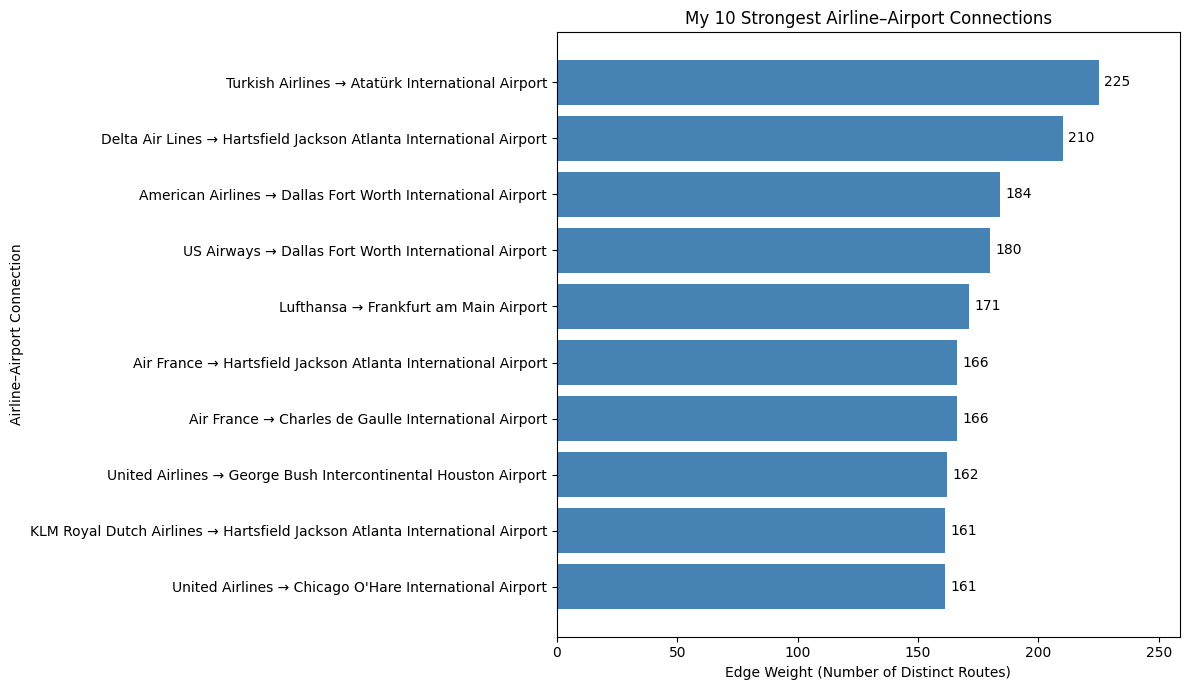

In [211]:
import matplotlib.pyplot as plt

# Select my 10 strongest connections
top_edges = edge_weights.nlargest(10, 'Weight').copy()

# Add airline names
top_edges = top_edges.merge(
    airlines_selected[['Airline ID', 'Name']].rename(
        columns={'Name': 'Airline Name'}
    ),
    on='Airline ID',
    how='left',
    validate='many_to_one'
)

# Add airport names
top_edges = top_edges.merge(
    airports_selected[['Airport ID', 'Name']].rename(
        columns={'Name': 'Airport Name'}
    ),
    on='Airport ID',
    how='left',
    validate='many_to_one'
)

# Create labels for my chart
top_edges['Connection'] = (
    top_edges['Airline Name'] + ' → ' +
    top_edges['Airport Name']
)

# Sort for horizontal bar chart
top_edges = top_edges.sort_values('Weight')

# Create visualization
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_edges['Connection'],
    top_edges['Weight'],
    color='steelblue'
)

# Display weights at the end of each bar
plt.bar_label(bars, padding=4)

plt.title('My 10 Strongest Airline–Airport Connections')
plt.xlabel('Edge Weight (Number of Distinct Routes)')
plt.ylabel('Airline–Airport Connection')
plt.xlim(0, top_edges['Weight'].max() * 1.15)

plt.tight_layout()
plt.show()

# Edge Weight Counts

It means there are 9,800 unique airline-airport relationships where the airline has exactly one distinct recorded route involving that airport.

I examined the number of airline–airport connections at each edge weight. My results show that 9,800 connections (51.5%) have a weight of 1, while 3,925 connections have a weight of 2.

As edge weight increases, the number of connections decreases sharply.

This indicates that most airline-airport relationships involve relatively few distinct routes, while only a small number involve many routes.

# Visualize My Edge Weight Distribution Using a Line Chart

In my OpenFlights dataset, 9,800 airline-airport relationships have an edge weight of 1. This means that each of these relationships involves exactly one distinct recorded route.

**In other words, For each unique (Airline, Airport) key, I count the number of distinct other airports connected through recorded routes. This count represents the edge weight.**

So when I see 9,800 connections with weight 1, it means 9,800 unique airline-airport keys each have exactly one distinct other airport associated with them.

My edge weight analysis clearly shows that:

9,800 airline-airport relationships have an edge weight of 1.

3,925 airline-airport relationships have an edge weight of 2.

1,683 airline-airport relationships have an edge weight of 3.

The number of airline-airport relationships decreases sharply as edge weight increases, indicating that most relationships involve only a few distinct recorded routes.

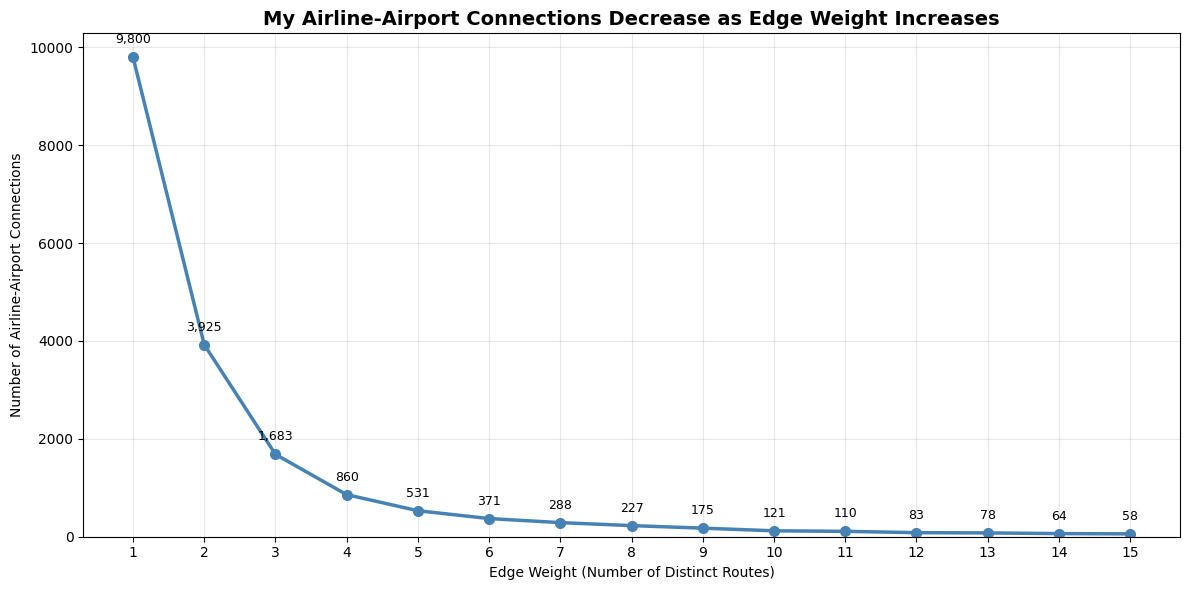

In [215]:
import matplotlib.pyplot as plt

# Count connections at each edge weight
weight_counts = (
    edge_weights['Weight']
    .value_counts()
    .sort_index()
)

# Select edge weights from 1 to 15
weight_counts_15 = weight_counts.reindex(
    range(1, 16), fill_value=0
)

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    weight_counts_15.index,
    weight_counts_15.values,
    marker='o',
    linewidth=2.5,
    markersize=7,
    color='steelblue'
)

# Add number labels to each point
for x, y in zip(weight_counts_15.index, weight_counts_15.values):
    plt.annotate(
        f'{y:,}',
        (x, y),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=9
    )

plt.title(
    'My Airline-Airport Connections Decrease as Edge Weight Increases',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Edge Weight (Number of Distinct Routes)')
plt.ylabel('Number of Airline-Airport Connections')

plt.xticks(range(1, 16))
plt.grid(True, alpha=0.3)

plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

In [222]:
import networkx as nx

# Create a copy of my original bipartite network
B_weighted = B.copy()

# Add calculated weights to airline-airport connections
for _, row in edge_weights.iterrows():

    airline = 'airline_' + str(int(row['Airline ID']))
    airport = 'airport_' + str(int(row['Airport ID']))

    B_weighted.edges[airline, airport]['weight'] = int(row['Weight'])

# Verify my weighted network
print("=== MY WEIGHTED BIPARTITE NETWORK ===")

print("Total Nodes:", B_weighted.number_of_nodes())
print("Total Edges:", B_weighted.number_of_edges())

weighted_edges = sum(
    'weight' in data
    for _, _, data in B_weighted.edges(data=True)
)

print("Edges with Weights:", weighted_edges)
print("Is Bipartite:", nx.is_bipartite(B_weighted))

=== MY WEIGHTED BIPARTITE NETWORK ===
Total Nodes: 3734
Total Edges: 19039
Edges with Weights: 19039
Is Bipartite: True


# Weaker airline-airport Relationship:

For each unique (Airline, Airport) combination, I count the number of distinct other airports connected through recorded routes. That count becomes the edge weight.

A weaker airline-airport relationship means an airline has relatively few distinct recorded routes involving that airport.

My OpenFlights dataset contains mostly weaker airline-airport relationships, based on the edge weight definition I selected.

- 51.5% = 9,800 / 19,039 * 100: More than half of my airline-airport relationships have exactly one distinct recorded route.

- 80.9% = 15,408 / 19,039 * 100: Most relationships involve only 1-3 distinct recorded routes.
- 6.2% = 1,179 / 19,039 * 100: Only a small percentage of relationships involve 10 or more distinct recorded routes.

My conclusion: Most airline-airport relationships in my network have low edge weights, while relatively few have high edge weights.

In [224]:
# Select route information from my original dataset
routes_table = routes_final[
    ['Airline ID', 'Source Airport ID', 'Destination Airport ID']
].copy()

# Add airline names
routes_table = routes_table.merge(
    airlines_selected[['Airline ID', 'Name']],
    on='Airline ID',
    how='left'
).rename(columns={'Name': 'Airline Name'})

# Add source airport names
routes_table = routes_table.merge(
    airports_selected[['Airport ID', 'Name']],
    left_on='Source Airport ID',
    right_on='Airport ID',
    how='left'
).rename(columns={'Name': 'Source Airport'})

routes_table = routes_table.drop(columns=['Airport ID'])

# Add destination airport names
routes_table = routes_table.merge(
    airports_selected[['Airport ID', 'Name']],
    left_on='Destination Airport ID',
    right_on='Airport ID',
    how='left'
).rename(columns={'Name': 'Destination Airport'})

routes_table = routes_table.drop(columns=['Airport ID'])

# Match each route's source airport to its airline-airport edge weight
routes_table = routes_table.merge(
    edge_weights.rename(columns={
        'Airport ID': 'Source Airport ID',
        'Weight': 'Edge Weight'
    }),
    on=['Airline ID', 'Source Airport ID'],
    how='left'
)

# Display the first 20 routes in ascending edge weight order
display(
    routes_table[
        ['Airline Name', 'Source Airport',
         'Destination Airport', 'Edge Weight']
    ].sort_values(
        'Edge Weight', ascending=True
    ).head(10)
)

,Airline Name,Source Airport,Destination Airport,Edge Weight
9669,Air France,Valencia Airport,Charles de Gaulle International Airport,1
9666,Air France,Vigo Airport,Charles de Gaulle International Airport,1
9659,Air France,McGhee Tyson Airport,Hartsfield Jackson Atlanta International Airport,1
9656,Air France,Tucson International Airport,Hartsfield Jackson Atlanta International Airport,1
9653,Air France,Tulsa International Airport,Hartsfield Jackson Atlanta International Airport,1
9652,Air France,Turin Airport,Charles de Gaulle International Airport,1
9651,Air France,Tri-Cities Regional TN/VA Airport,Hartsfield Jackson Atlanta International Airport,1
9648,Air France,Tampa International Airport,Hartsfield Jackson Atlanta International Airport,1
9647,Air France,Ivato Airport,Charles de Gaulle International Airport,1
9692,Air Algerie,Port Bouet Airport,Houari Boumediene Airport,1


Displaying Edge wieght in descending order

In [225]:
import pandas as pd

# Convert my weighted network edges into a table
weighted_network_df = pd.DataFrame(
    [
        {
            'Airline ID': int(airline.split('_')[1]),
            'Airport ID': int(airport.split('_')[1]),
            'Edge Weight': data['weight']
        }
        for airline, airport, data in B_weighted.edges(data=True)
        if airline.startswith('airline_')
    ]
)

# Add airline names
weighted_network_df = weighted_network_df.merge(
    airlines_selected[['Airline ID', 'Name']],
    on='Airline ID',
    how='left'
).rename(columns={'Name': 'Airline Name'})

# Add airport names
weighted_network_df = weighted_network_df.merge(
    airports_selected[['Airport ID', 'Name']],
    on='Airport ID',
    how='left'
).rename(columns={'Name': 'Airport Name'})

# Display the top 10 strongest relationships
display(
    weighted_network_df[
        ['Airline Name', 'Airport Name', 'Edge Weight']
    ].sort_values('Edge Weight', ascending=False).head(10)
)

,Airline Name,Airport Name,Edge Weight
15337,Turkish Airlines,Atatürk International Airport,225
5646,Delta Air Lines,Hartsfield Jackson Atlanta International Airport,210
1564,American Airlines,Dallas Fort Worth International Airport,184
16943,US Airways,Dallas Fort Worth International Airport,180
10657,Lufthansa,Frankfurt am Main Airport,171
2455,Air France,Hartsfield Jackson Atlanta International Airport,166
2457,Air France,Charles de Gaulle International Airport,166
16256,United Airlines,George Bush Intercontinental Houston Airport,162
16249,United Airlines,Chicago O'Hare International Airport,161
9874,KLM Royal Dutch Airlines,Hartsfield Jackson Atlanta International Airport,161


I have created my weighted bipartite network and displayed the 10 strongest airline-airport relationships.

My next step is to apply the Island Method, which is an important part of my project objectives.

# Apply the Island Method

What happens to my airline-airport network when I remove relationships with fewer than 10 distinct recorded routes?

I will start with a minimum edge weight of 10.

# What is an island?

An island is a group of nodes that are connected to one another, but have no remaining connections to nodes in other islands.

### My Island Method Findings (Edge Weight ≥ 10)

- **Minimum Edge Weight:** I applied a threshold of 10 to focus on airline-airport relationships involving at least 10 distinct recorded routes.

- **Remaining Nodes:** 756 airline and airport nodes remain in my filtered network.

- **Remaining Edges:** 1,179 airline-airport relationships meet the threshold.

- **Number of Islands:** My network forms **74 separate connected groups (islands)**.

- **Largest Island (Island 1):** Contains 539 nodes, representing approximately 71.3% (539/756) of the remaining network.

- **Other 73 Islands:** Contain a combined total of 217 nodes (756 - 539), representing approximately 28.7% of the remaining network.

- **Key Finding:** Most remaining nodes (71.3%) belong to one large connected island, while the other 73 islands contain smaller, separate groups of airlines and airports. This suggests that many higher-route-diversity relationships remain interconnected within one major network, while others form isolated groups.

In [255]:
import networkx as nx

# Set my minimum edge weight
threshold = 10

# Create a network containing only qualifying connections
island_graph = nx.Graph()

for airline, airport, data in B_weighted.edges(data=True):

    if data['weight'] >= threshold:
        island_graph.add_edge(
            airline,
            airport,
            weight=data['weight']
        )

# Identify connected groups (islands)
islands = list(nx.connected_components(island_graph))

# Display my results
print("=== MY ISLAND METHOD RESULTS ===")
print("Minimum Edge Weight:", threshold)
print("Remaining Nodes:", island_graph.number_of_nodes())
print("Remaining Edges:", island_graph.number_of_edges())
print("Number of Islands:", len(islands))
print("Largest Island Size:", max(len(i) for i in islands))

=== MY ISLAND METHOD RESULTS ===
Minimum Edge Weight: 10
Remaining Nodes: 756
Remaining Edges: 1179
Number of Islands: 74
Largest Island Size: 539


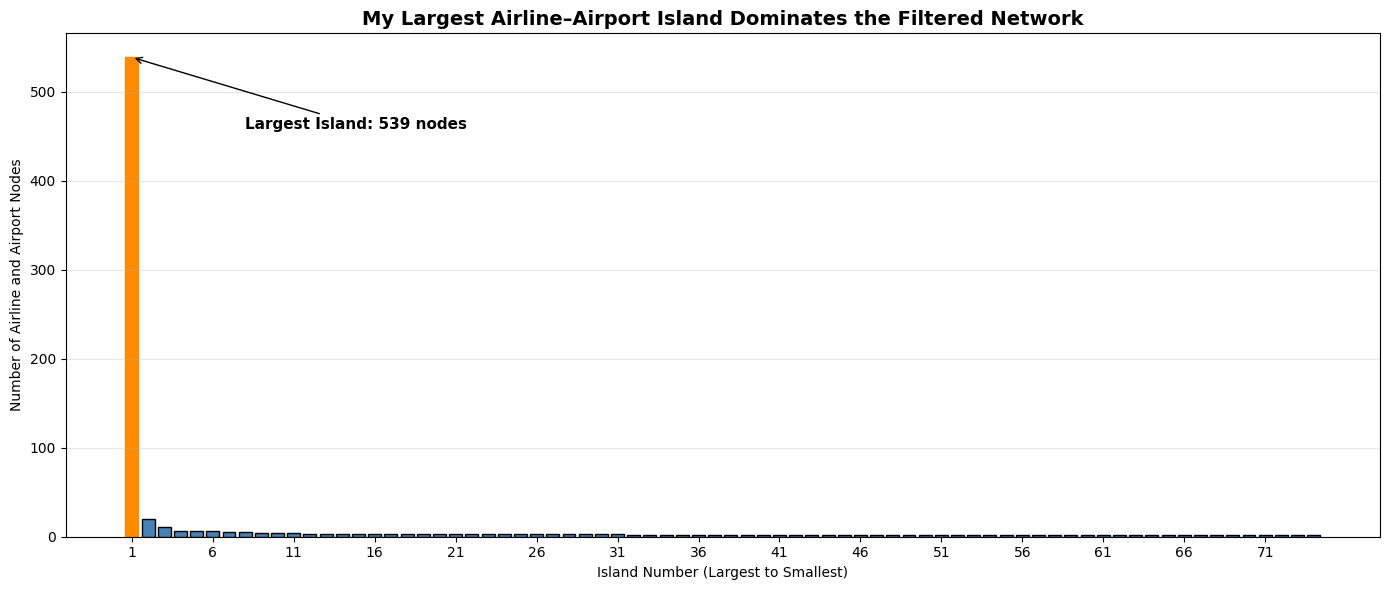

In [256]:
import matplotlib.pyplot as plt

# Sort my islands from largest to smallest
sorted_islands = sorted(islands, key=len, reverse=True)

# Count the number of nodes in each island
island_sizes = [len(group) for group in sorted_islands]

# Create my island size chart
plt.figure(figsize=(14, 6))

bars = plt.bar(
    range(1, len(island_sizes) + 1),
    island_sizes,
    color='steelblue',
    edgecolor='black'
)

# Highlight my largest island
bars[0].set_color('darkorange')

# Label the largest island
plt.annotate(
    f'Largest Island: {island_sizes[0]} nodes',
    xy=(1, island_sizes[0]),
    xytext=(8, island_sizes[0] * 0.85),
    fontsize=11,
    fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='black')
)

plt.title(
    'My Largest Airline–Airport Island Dominates the Filtered Network',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Island Number (Largest to Smallest)')
plt.ylabel('Number of Airline and Airport Nodes')

plt.xticks(range(1, len(island_sizes) + 1, 5))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

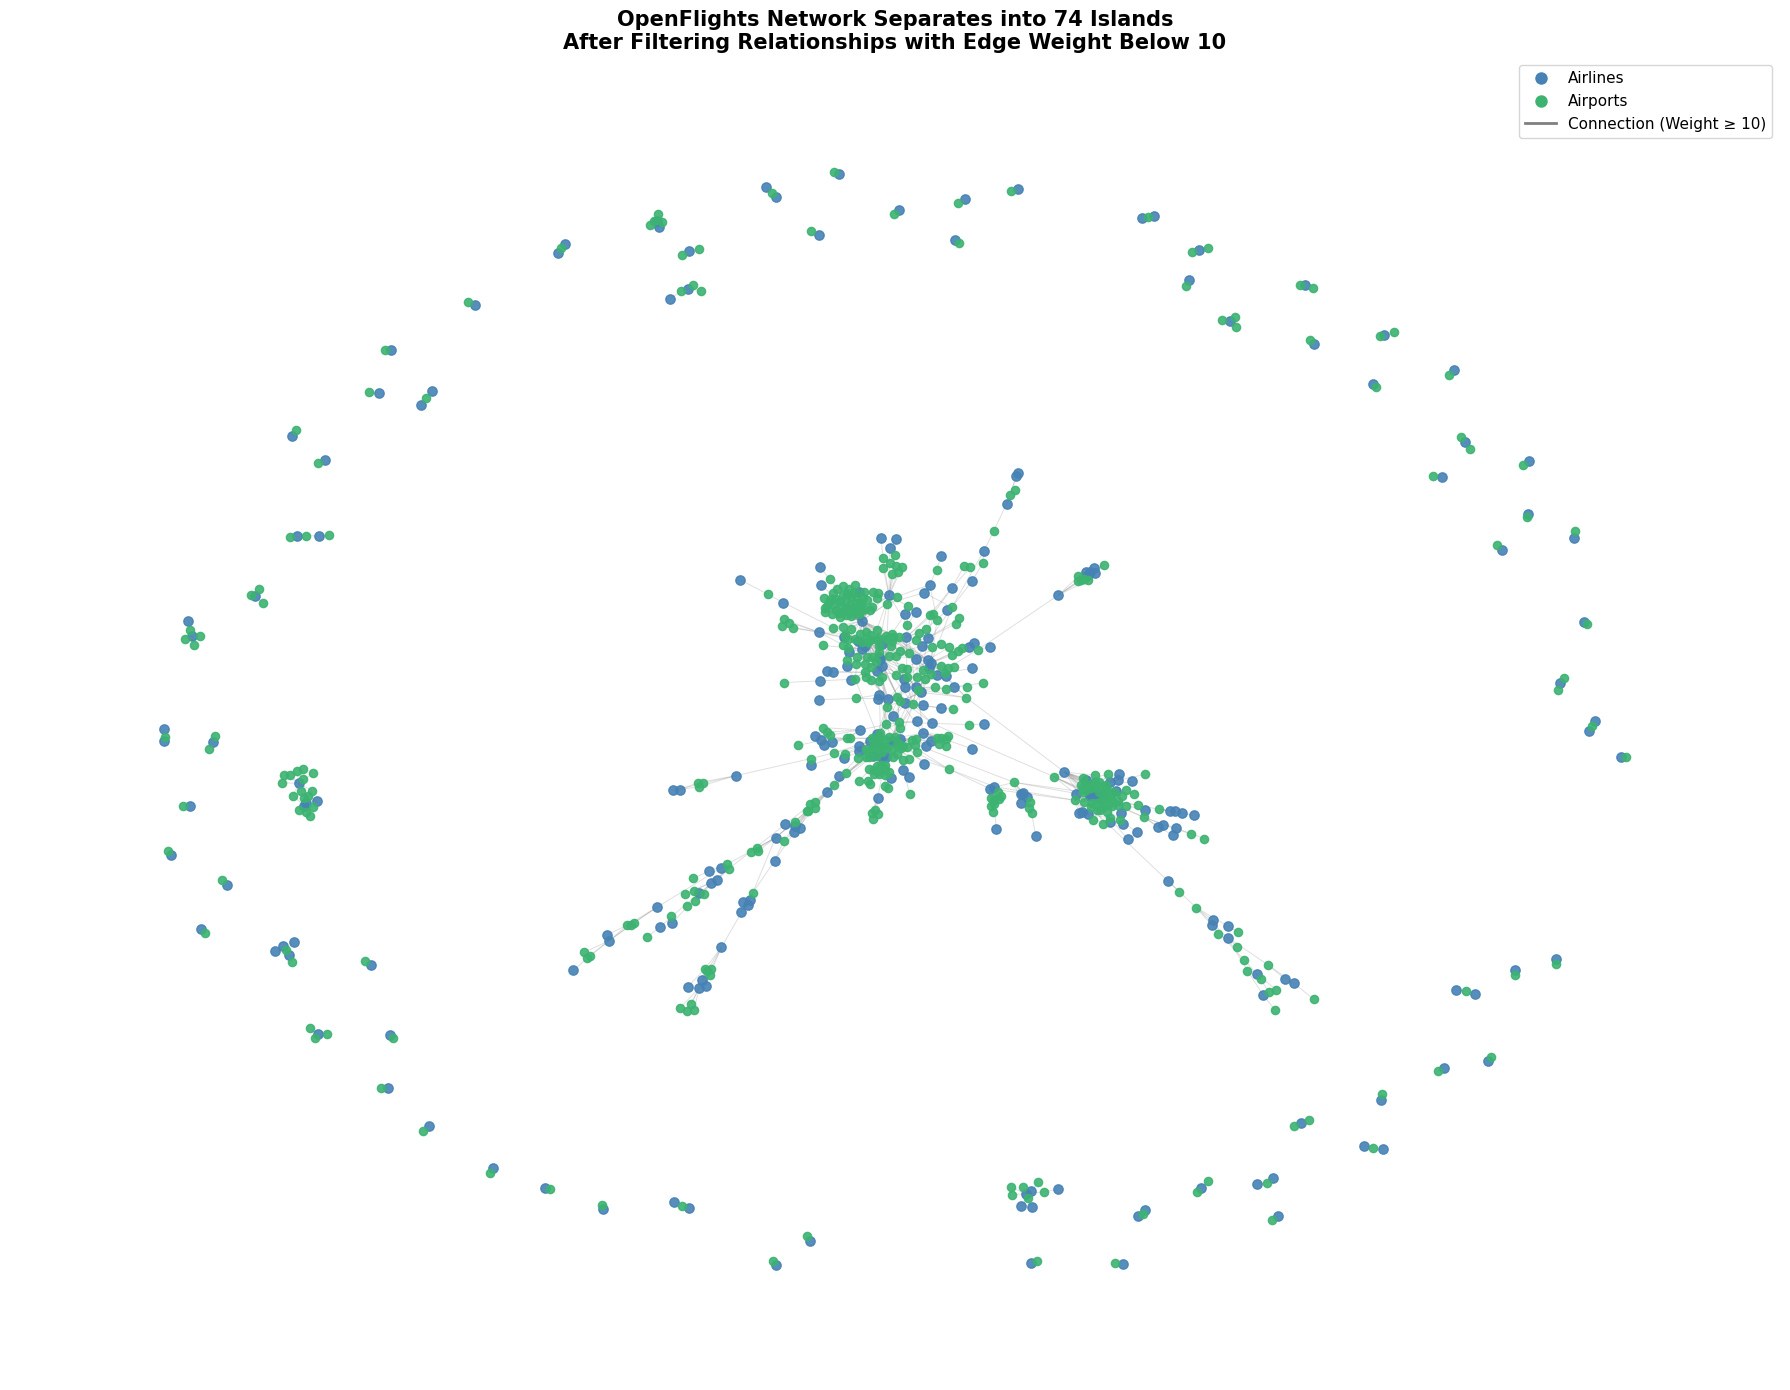

# Interactive Network Visualization for All 74 Islands

In [258]:
import networkx as nx
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Create a function to visualize a selected island
def visualize_island(island_number):

    # Select island (Python indexing starts at 0)
    selected_nodes = sorted_islands[island_number - 1]

    # Create subgraph
    G = island_graph.subgraph(selected_nodes).copy()

    # Separate airline and airport nodes
    airline_nodes = [
        n for n in G.nodes()
        if n.startswith('airline_')
    ]

    airport_nodes = [
        n for n in G.nodes()
        if n.startswith('airport_')
    ]

    # Create labels using IATA codes when available
    airline_codes = dict(zip(
        airlines_selected['Airline ID'].astype(int),
        airlines_selected['IATA']
    ))

    airport_codes = dict(zip(
        airports_selected['Airport ID'].astype(int),
        airports_selected['IATA']
    ))

    labels = {}

    for node in airline_nodes:
        node_id = int(node.split('_')[1])
        code = airline_codes.get(node_id)
        labels[node] = (
            str(code) if code and str(code) not in ['nan', '\\N']
            else str(node_id)
        )

    for node in airport_nodes:
        node_id = int(node.split('_')[1])
        code = airport_codes.get(node_id)
        labels[node] = (
            str(code) if code and str(code) not in ['nan', '\\N']
            else str(node_id)
        )

    # Layout
    pos = nx.spring_layout(
        G,
        seed=42,
        k=1.5 / (len(G.nodes()) ** 0.5),
        iterations=150
    )

    plt.figure(figsize=(14, 10))

    # Draw connections
    nx.draw_networkx_edges(
        G, pos,
        edge_color='skyblue',
        alpha=0.5,
        width=0.8
    )

    # Draw airline nodes
    nx.draw_networkx_nodes(
        G, pos,
        nodelist=airline_nodes,
        node_color='cornflowerblue',
        node_size=300,
        label='Airlines'
    )

    # Draw airport nodes
    nx.draw_networkx_nodes(
        G, pos,
        nodelist=airport_nodes,
        node_color='olivedrab',
        node_size=200,
        label='Airports'
    )

    # Draw labels
    nx.draw_networkx_labels(
        G, pos,
        labels=labels,
        font_size=7
    )

    plt.title(
        f'Island {island_number}: Airline–Airport Network\n'
        f'{len(airline_nodes)} Airlines | '
        f'{len(airport_nodes)} Airports | '
        f'{G.number_of_edges()} Connections',
        fontsize=14,
        fontweight='bold'
    )

    plt.legend()
    plt.axis('off')
    plt.tight_layout()
    plt.show()


# Create an interactive dropdown
island_selector = widgets.Dropdown(
    options=[
        (f'Island {i}', i)
        for i in range(1, len(sorted_islands) + 1)
    ],
    value=1,
    description='Select Island:'
)

# Display selected island
widgets.interact(
    visualize_island,
    island_number=island_selector
)

interactive(children=(Dropdown(description='Select Island:', options=(('Island 1', 1), ('Island 2', 2), ('Isla…

<function __main__.visualize_island(island_number)>

# Analyze Island 1:

In [264]:
# Select largest island
largest_island = sorted_islands[0]

# Separate airline nodes and airport nodes
largest_airlines = [
    node for node in largest_island
    if node.startswith('airline_')
]

largest_airports = [
    node for node in largest_island
    if node.startswith('airport_')
]

print("=== LARGEST ISLAND COMPOSITION ===")
print("Total Nodes:", len(largest_island))
print("Number of Airlines:", len(largest_airlines))
print("Number of Airports:", len(largest_airports))

=== LARGEST ISLAND COMPOSITION ===
Total Nodes: 539
Number of Airlines: 177
Number of Airports: 362


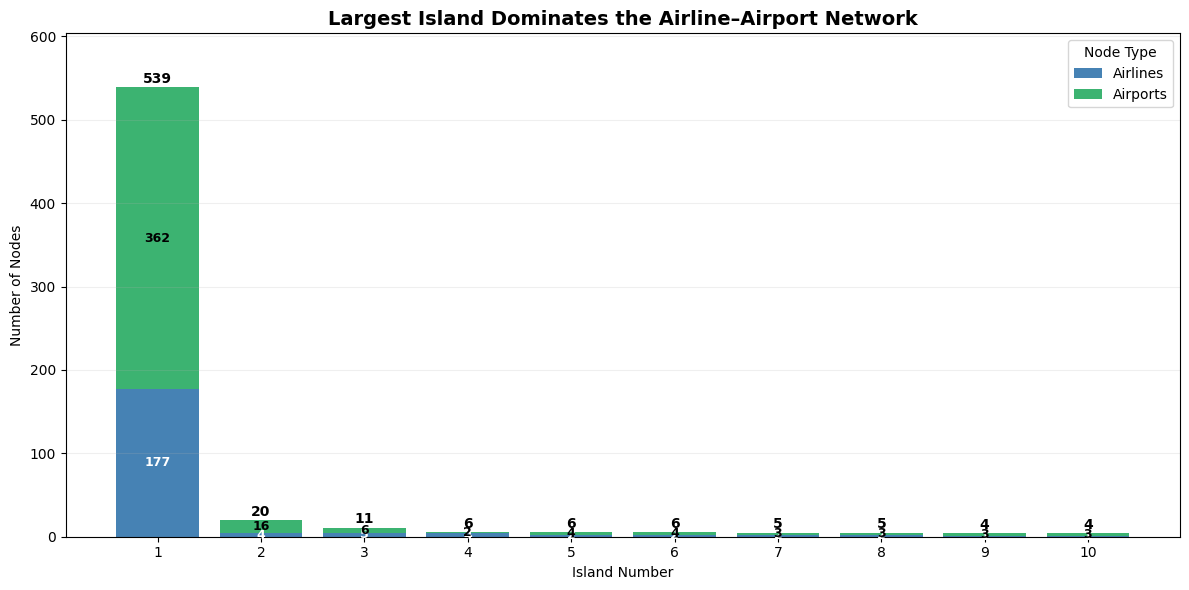

In [263]:
import matplotlib.pyplot as plt

df = island_summary_df.copy()

fig, ax = plt.subplots(figsize=(12, 6))

# Blue bars: Airlines
bars_airlines = ax.bar(
    df['Island'],
    df['Airlines'],
    color='steelblue',
    label='Airlines'
)

# Green bars: Airports
bars_airports = ax.bar(
    df['Island'],
    df['Airports'],
    bottom=df['Airlines'],
    color='mediumseagreen',
    label='Airports'
)

# Label both colored sections
for i, row in df.iterrows():

    x = row['Island']

    # Airline count inside blue section
    ax.text(
        x,
        row['Airlines'] / 2,
        str(row['Airlines']),
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='white'
    )

    # Airport count inside green section
    ax.text(
        x,
        row['Airlines'] + row['Airports'] / 2,
        str(row['Airports']),
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='black'
    )

    # Total nodes above each bar
    ax.text(
        x,
        row['Total Nodes'] + 5,
        str(row['Total Nodes']),
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    'Largest Island Dominates the Airline–Airport Network',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Island Number')
ax.set_ylabel('Number of Nodes')
ax.set_xticks(df['Island'])
ax.set_ylim(0, df['Total Nodes'].max() * 1.12)

ax.legend(title='Node Type')
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

# Degree Centrality

Which airlines and airports have the most connections within Island 1?
This will help you understand which nodes dominate the largest connected group.

In [265]:
import pandas as pd
import networkx as nx

# Create the subgraph for Island 1
largest_island_graph = island_graph.subgraph(
    largest_island
).copy()

# Calculate airline degrees within Island 1
airline_results = []

for node in largest_airlines:
    airline_id = int(node.split('_')[1])

    airline_results.append({
        'Airline ID': airline_id,
        'Degree': largest_island_graph.degree(node)
    })

# Create a DataFrame
island_airline_degree = pd.DataFrame(airline_results)

# Add airline names
island_airline_degree = island_airline_degree.merge(
    airlines_selected[['Airline ID', 'Name']],
    on='Airline ID',
    how='left'
)

# Display the top 10 airlines
top_10_airlines = (
    island_airline_degree
    .sort_values('Degree', ascending=False)
    .head(10)
)

display(top_10_airlines[['Name', 'Degree']])

,Name,Degree
18,Ryanair,78
156,China Southern Airlines,42
41,easyJet,36
68,Air China,36
176,Delta Air Lines,34
101,China Eastern Airlines,33
36,Southwest Airlines,33
174,American Airlines,31
53,AirTran Airways,29
32,United Airlines,27


- Ryanair has the highest degree (78), indicating that it connects to the most airports in Island 1.
- China Southern Airlines ranks second with 42 airport connections.
- easyJet and Air China each connect to 36 airports.
- These results show that airline connectivity is unevenly distributed within Island 1.
Key finding: Ryanair has substantially more qualifying airport connections than other airlines in Island 1, making it a highly connected node in the filtered network.

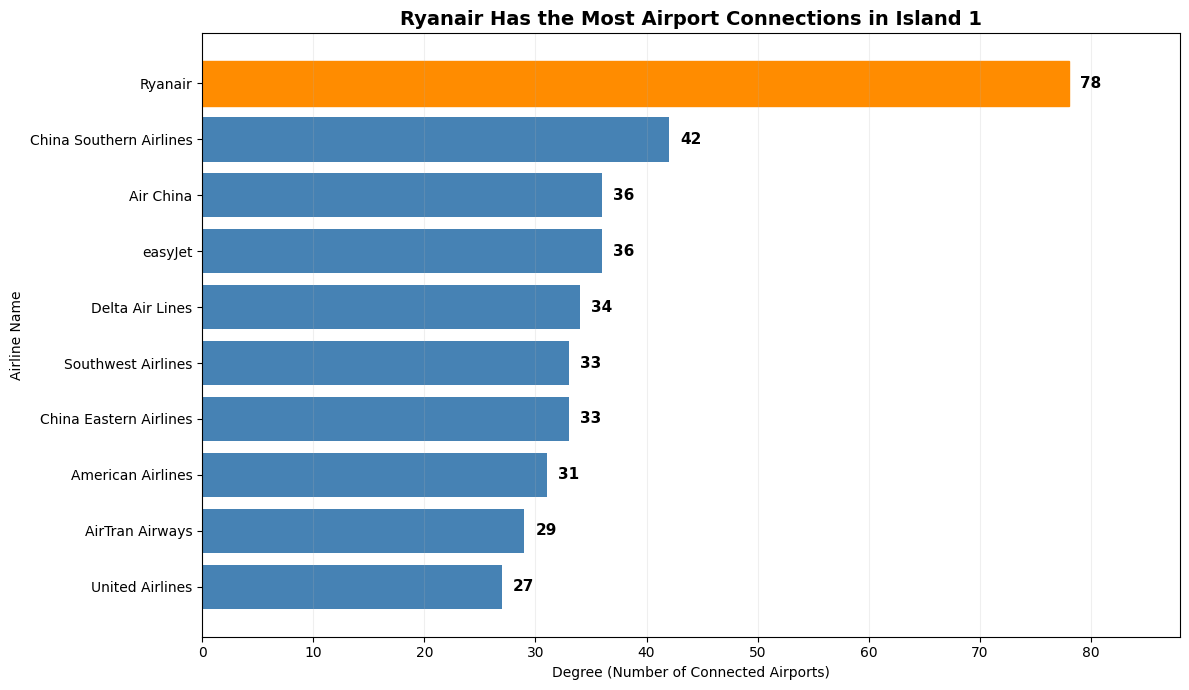

In [266]:
import matplotlib.pyplot as plt

# Sort airlines for horizontal bar chart
plot_data = top_10_airlines.sort_values('Degree')

plt.figure(figsize=(12, 7))

# Create horizontal bars
bars = plt.barh(
    plot_data['Name'],
    plot_data['Degree'],
    color='steelblue'
)

# Highlight the airline with the highest degree
bars[-1].set_color('darkorange')

# Label every bar with its degree
for bar in bars:
    value = bar.get_width()

    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{int(value)}',
        va='center',
        fontsize=11,
        fontweight='bold'
    )

plt.title(
    'Ryanair Has the Most Airport Connections in Island 1',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Degree (Number of Connected Airports)')
plt.ylabel('Airline Name')

plt.xlim(0, plot_data['Degree'].max() + 10)
plt.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

Visualize the 10 Most Connected Airports in Island 1

- Atlanta Airport has the highest degree (11), meaning it connects to 11 airlines in the filtered network.
- JFK, Chongqing, and Palma de Mallorca each connect to 10 airlines.
- Los Angeles, Frankfurt, Manchester, Heathrow, and Xi'an each connect to 9 airlines.
- Brussels connects to 8 airlines.
Key finding: Atlanta has the most direct airline connections in Island 1, but the difference between the top airports is relatively small.

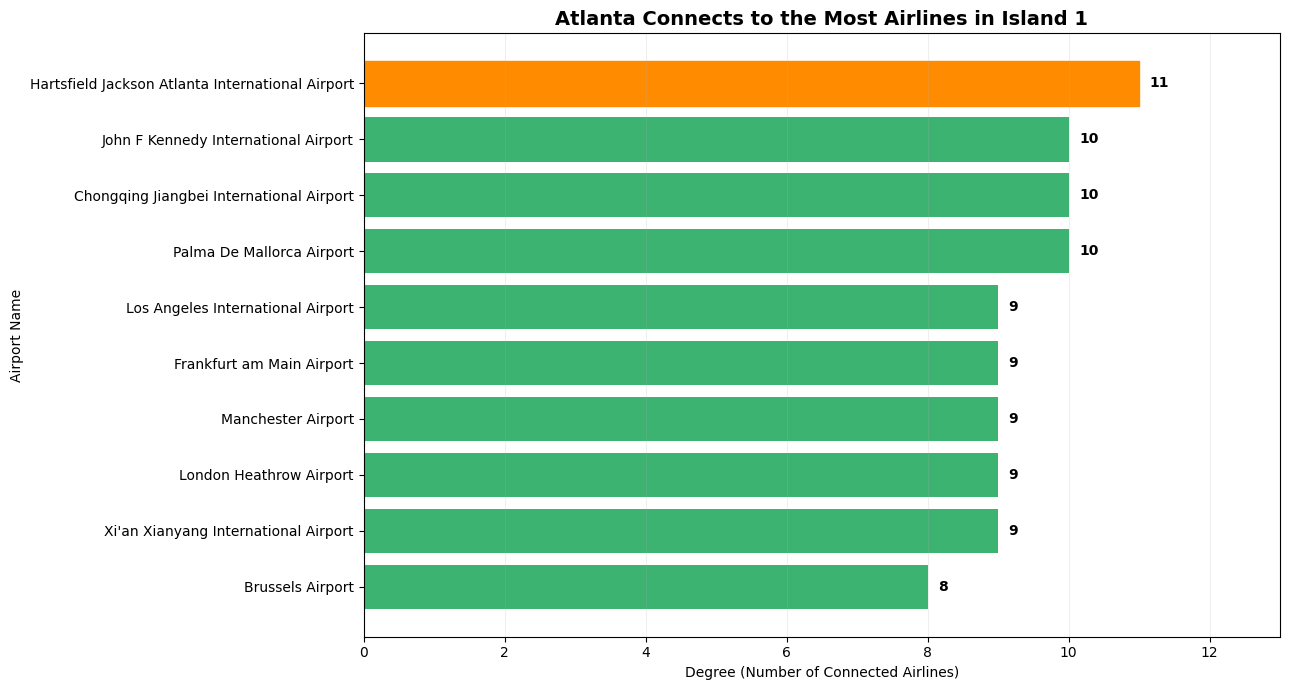

In [267]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate airport degree within Island 1
airport_results = []

for node in largest_island_graph.nodes():

    if node.startswith('airport_'):
        airport_id = int(node.split('_')[1])

        airport_results.append({
            'Airport ID': airport_id,
            'Degree': largest_island_graph.degree(node)
        })

# Create DataFrame
island_airport_degree = pd.DataFrame(airport_results)

# Add airport names
island_airport_degree = island_airport_degree.merge(
    airports_selected[['Airport ID', 'Name']],
    on='Airport ID',
    how='left'
)

# Select top 10 airports
top_10_airports = (
    island_airport_degree
    .sort_values('Degree', ascending=False)
    .head(10)
    .sort_values('Degree')
)

# Create chart
plt.figure(figsize=(13, 7))

bars = plt.barh(
    top_10_airports['Name'],
    top_10_airports['Degree'],
    color='mediumseagreen'
)

# Highlight the most connected airport
bars[-1].set_color('darkorange')

# Add degree labels
for bar in bars:
    value = bar.get_width()

    plt.text(
        value + 0.15,
        bar.get_y() + bar.get_height() / 2,
        str(int(value)),
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.title(
    'Atlanta Connects to the Most Airlines in Island 1',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Degree (Number of Connected Airlines)')
plt.ylabel('Airport Name')

plt.xlim(0, top_10_airports['Degree'].max() + 2)
plt.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

# Betweenness Centrality

Which airlines and airports act as bridges connecting different parts of Island 1?
Betweenness centrality helps answer this question.

### Betweenness Centrality Findings

- Ryanair has the highest betweenness centrality (0.2265), followed closely by Delta Air Lines (0.2250).

- Delta has fewer direct airport connections than Ryanair but almost equal betweenness, showing that connection count and bridging importance are different.

- Incheon International Airport has the highest betweenness among airports, while Atlanta has the highest airport degree.

- These findings indicate that some airlines and airports occupy important positions along shortest paths connecting different parts of Island 1.

In [268]:
import networkx as nx
import pandas as pd

# Calculate betweenness centrality in Island 1
betweenness = nx.betweenness_centrality(
    largest_island_graph,
    normalized=True
)

# Create a results table
betweenness_df = pd.DataFrame({
    'Node': list(betweenness.keys()),
    'Betweenness': list(betweenness.values())
})

# Identify airlines and airports
betweenness_df['Type'] = betweenness_df['Node'].apply(
    lambda node: 'Airline'
    if node.startswith('airline_')
    else 'Airport'
)

# Add names
def get_node_name(node):
    node_id = int(node.split('_')[1])

    if node.startswith('airline_'):
        return airline_names.get(node_id, node)

    return airport_names.get(node_id, node)

betweenness_df['Name'] = betweenness_df['Node'].apply(
    get_node_name
)

# Display top 10
top_betweenness = (
    betweenness_df
    .sort_values('Betweenness', ascending=False)
    .head(10)
)

display(
    top_betweenness[['Name', 'Type', 'Betweenness']]
)

,Name,Type,Betweenness
283,Ryanair,Airline,0.226477
232,Delta Air Lines,Airline,0.224998
70,American Airlines,Airline,0.152671
34,Incheon International Airport,Airport,0.148512
492,easyJet,Airline,0.140159
101,Air Berlin,Airline,0.130774
499,United Airlines,Airline,0.124047
221,China Southern Airlines,Airline,0.101960
153,Alitalia,Airline,0.097892
505,US Airways,Airline,0.093168


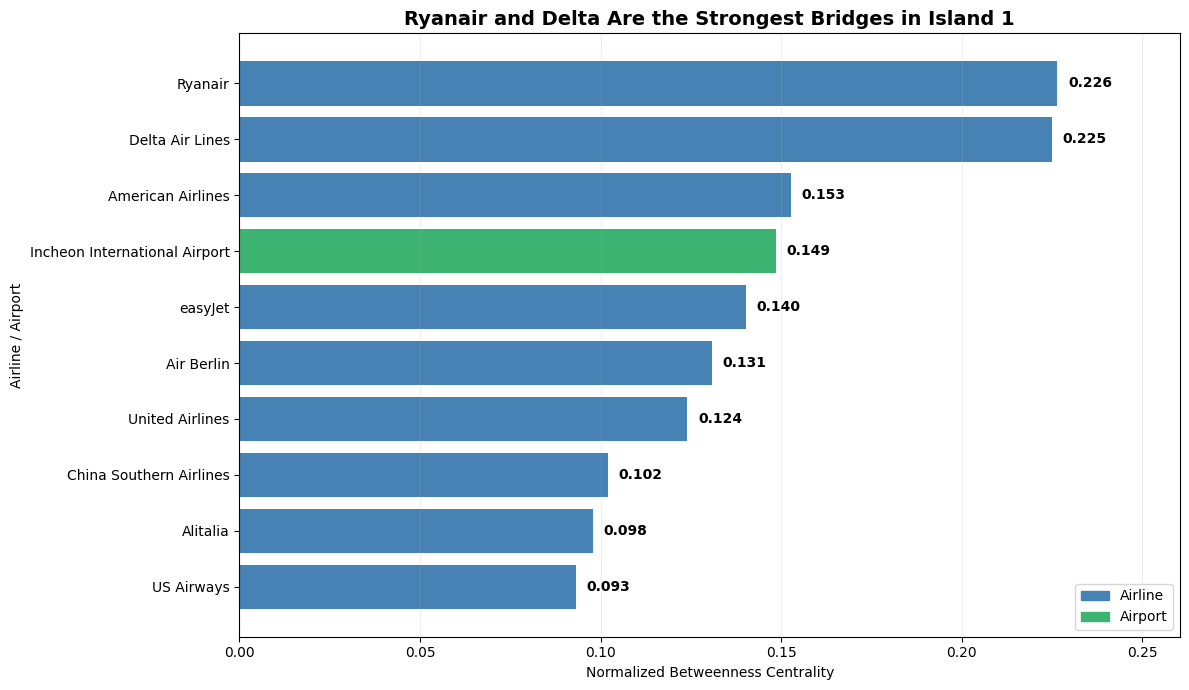

In [269]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Select top 10 nodes
plot_data = (
    betweenness_df
    .sort_values('Betweenness', ascending=False)
    .head(10)
    .sort_values('Betweenness')
)

# Assign colors
colors = [
    'steelblue' if t == 'Airline' else 'mediumseagreen'
    for t in plot_data['Type']
]

plt.figure(figsize=(12, 7))

bars = plt.barh(
    plot_data['Name'],
    plot_data['Betweenness'],
    color=colors
)

# Add values to each bar
for bar in bars:
    value = bar.get_width()

    plt.text(
        value + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.3f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.title(
    'Ryanair and Delta Are the Strongest Bridges in Island 1',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Normalized Betweenness Centrality')
plt.ylabel('Airline / Airport')

plt.xlim(0, plot_data['Betweenness'].max() * 1.15)
plt.grid(axis='x', alpha=0.2)

plt.legend(handles=[
    Patch(color='steelblue', label='Airline'),
    Patch(color='mediumseagreen', label='Airport')
])

plt.tight_layout()
plt.show()

# Top 10 Airports by Betweenness Centrality

,Name,Betweenness
34,Incheon International Airport,0.148512
189,Beijing Capital International Airport,0.092052
19,Berlin-Tegel Airport,0.089838
55,Hartsfield Jackson Atlanta International Airport,0.074191
81,John F Kennedy International Airport,0.069188
42,Domodedovo International Airport,0.069047
85,Narita International Airport,0.068851
341,Humberto Delgado Airport (Lisbon Portela Airport),0.065983
108,Frankfurt am Main Airport,0.064851
191,Hangzhou Xiaoshan International Airport,0.063991


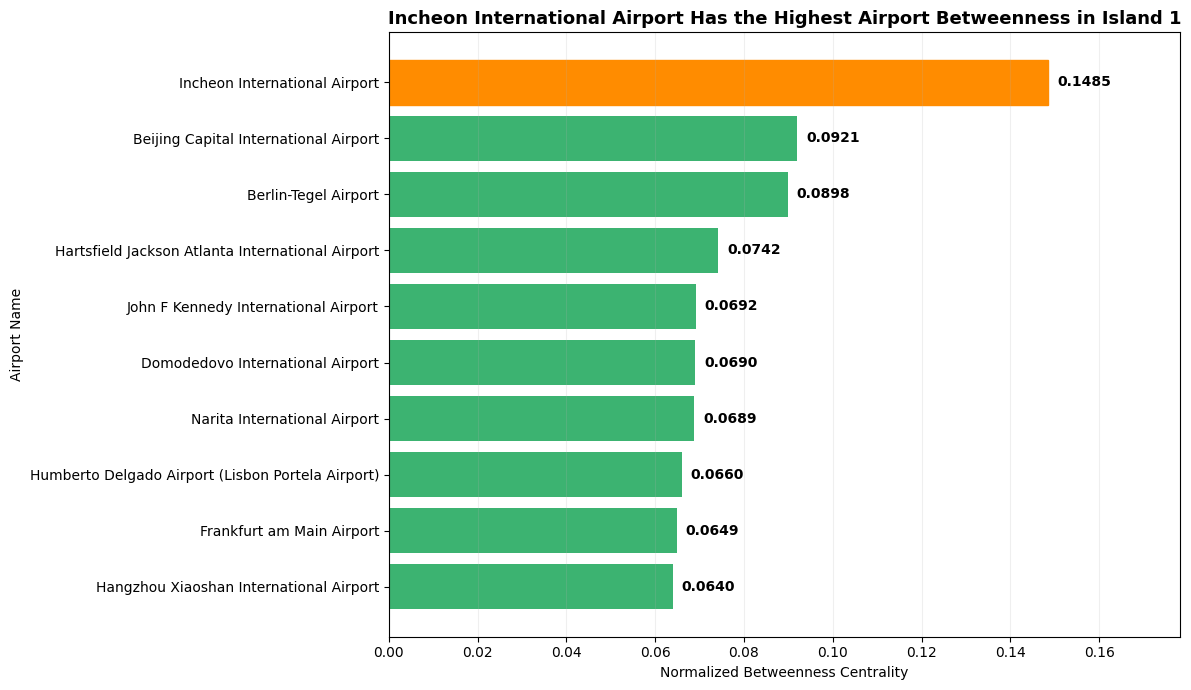

In [270]:
import matplotlib.pyplot as plt

# Select only airports
airport_betweenness = betweenness_df[
    betweenness_df['Type'] == 'Airport'
]

# Select top 10 airports
top_airport_betweenness = (
    airport_betweenness
    .sort_values('Betweenness', ascending=False)
    .head(10)
    .sort_values('Betweenness')
)

# Display results
display(
    top_airport_betweenness[
        ['Name', 'Betweenness']
    ].sort_values('Betweenness', ascending=False)
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_airport_betweenness['Name'],
    top_airport_betweenness['Betweenness'],
    color='mediumseagreen'
)

# Highlight the airport with highest betweenness
bars[-1].set_color('darkorange')

# Add value labels
for bar in bars:
    value = bar.get_width()

    plt.text(
        value + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.4f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.title(
    'Incheon International Airport Has the Highest '
    'Airport Betweenness in Island 1',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Normalized Betweenness Centrality')
plt.ylabel('Airport Name')

plt.xlim(
    0,
    top_airport_betweenness['Betweenness'].max() * 1.2
)

plt.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

# Closeness Centrality in Island 1

Closeness centrality measures how close a node is to other nodes in the network.

For example, an airline with high closeness can reach other airlines and airports through relatively short network paths.

### Closeness Centrality Findings

- Delta Air Lines has the highest airline closeness centrality (0.2475), followed by United Airlines (0.2368) and US Airways (0.2349).

- JFK International Airport has the highest airport closeness centrality (0.2435), followed by London Heathrow (0.2384) and Atlanta (0.2371).

- Although Ryanair has the highest airline degree and betweenness, Delta has the highest closeness centrality.

- Similarly, Atlanta has the highest airport degree, Incheon has the highest airport betweenness, and JFK has the highest airport closeness.

- **Key Finding:** Different centrality measures identify different types of importance within Island 1. Degree measures direct connections, betweenness measures bridging positions, and closeness measures how centrally nodes are positioned relative to the rest of the network.

In [271]:
import networkx as nx
import pandas as pd

# Calculate closeness centrality for Island 1
closeness = nx.closeness_centrality(largest_island_graph)

# Create a DataFrame
closeness_df = pd.DataFrame({
    'Node': list(closeness.keys()),
    'Closeness': list(closeness.values())
})

# Identify airlines and airports
closeness_df['Type'] = closeness_df['Node'].apply(
    lambda node: 'Airline'
    if node.startswith('airline_')
    else 'Airport'
)

# Add airline and airport names
closeness_df['Name'] = closeness_df['Node'].apply(
    get_node_name
)

# Display top 10 airlines
print("TOP 10 AIRLINES BY CLOSENESS")

display(
    closeness_df[
        closeness_df['Type'] == 'Airline'
    ][['Name', 'Closeness']]
    .sort_values('Closeness', ascending=False)
    .head(10)
)

# Display top 10 airports
print("TOP 10 AIRPORTS BY CLOSENESS")

display(
    closeness_df[
        closeness_df['Type'] == 'Airport'
    ][['Name', 'Closeness']]
    .sort_values('Closeness', ascending=False)
    .head(10)
)

TOP 10 AIRLINES BY CLOSENESS


,Name,Closeness
232,Delta Air Lines,0.247470
499,United Airlines,0.236796
505,US Airways,0.234934
101,Air Berlin,0.234321
492,easyJet,0.232097
70,American Airlines,0.230308
150,Finnair,0.228547
153,Alitalia,0.227966
374,Iberia Airlines,0.226813
123,Air France,0.223794


TOP 10 AIRPORTS BY CLOSENESS


,Name,Closeness
81,John F Kennedy International Airport,0.243549
77,London Heathrow Airport,0.238370
55,Hartsfield Jackson Atlanta International Airport,0.237109
128,Amsterdam Airport Schiphol,0.233406
124,Charles de Gaulle International Airport,0.232800
74,Los Angeles International Airport,0.232397
96,San Francisco International Airport,0.230802
94,Orlando International Airport,0.230210
57,General Edward Lawrence Logan International Ai...,0.229816
83,Miami International Airport,0.228450


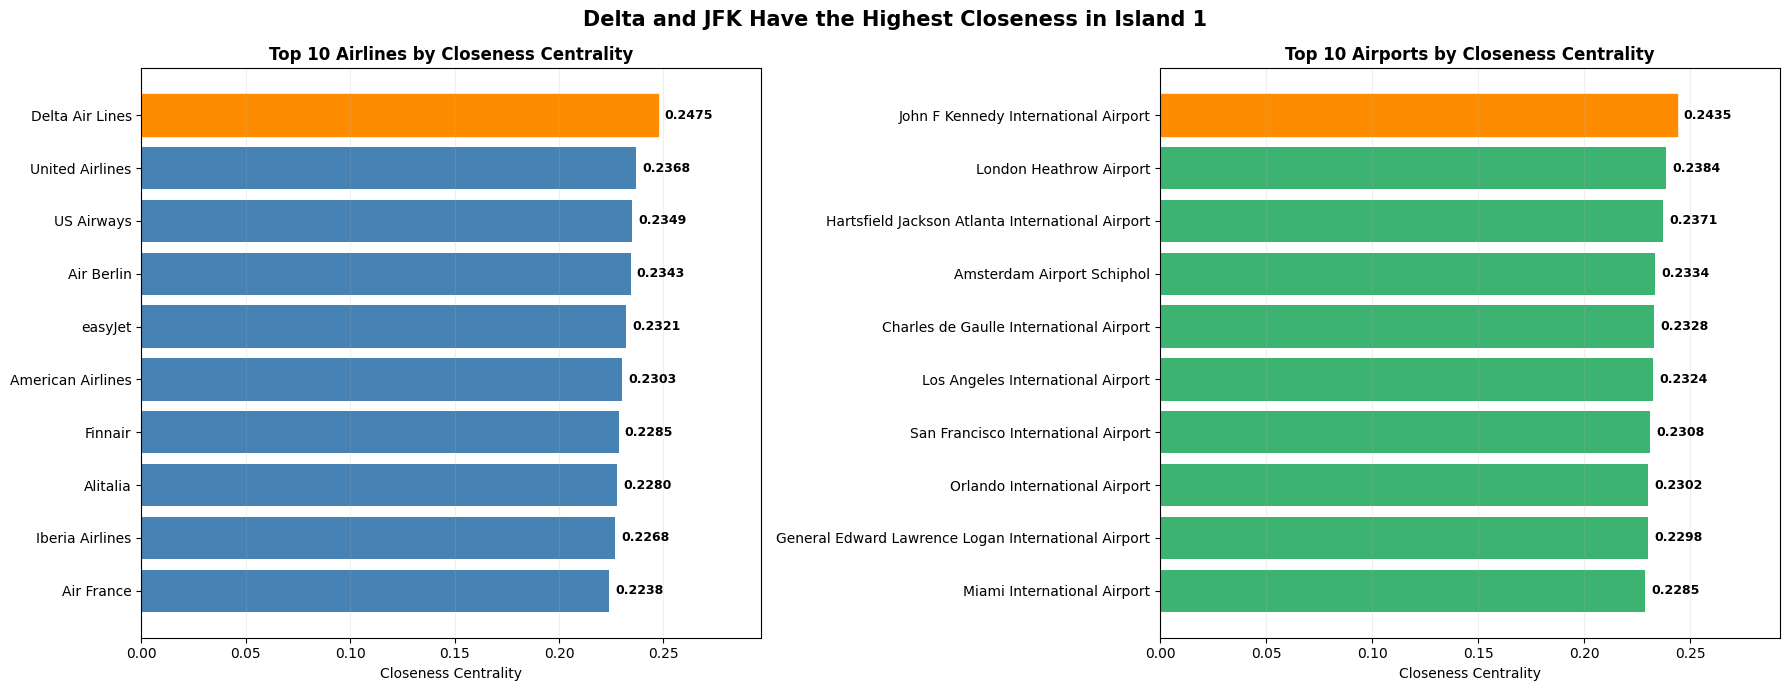

In [272]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, node_type, color in [
    (axes[0], 'Airline', 'steelblue'),
    (axes[1], 'Airport', 'mediumseagreen')
]:

    top = (
        closeness_df[closeness_df['Type'] == node_type]
        .sort_values('Closeness', ascending=False)
        .head(10)
        .sort_values('Closeness')
    )

    bars = ax.barh(
        top['Name'],
        top['Closeness'],
        color=color
    )

    # Highlight highest closeness
    bars[-1].set_color('darkorange')

    # Add value labels
    for bar in bars:
        value = bar.get_width()

        ax.text(
            value + 0.003,
            bar.get_y() + bar.get_height() / 2,
            f'{value:.4f}',
            va='center',
            fontsize=9,
            fontweight='bold'
        )

    ax.set_title(
        f'Top 10 {node_type}s by Closeness Centrality',
        fontweight='bold'
    )

    ax.set_xlabel('Closeness Centrality')
    ax.set_xlim(0, top['Closeness'].max() * 1.2)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle(
    'Delta and JFK Have the Highest Closeness in Island 1',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Eigenvector Centrality in Island 1


In [273]:
import networkx as nx
import pandas as pd

# Calculate eigenvector centrality for Island 1
eigenvector = nx.eigenvector_centrality(
    largest_island_graph,
    max_iter=5000,
    tol=1e-6
)

# Create a DataFrame
eigenvector_df = pd.DataFrame({
    'Node': list(eigenvector.keys()),
    'Eigenvector': list(eigenvector.values())
})

# Identify node type
eigenvector_df['Type'] = eigenvector_df['Node'].apply(
    lambda node: 'Airline'
    if node.startswith('airline_')
    else 'Airport'
)

# Add airline and airport names
eigenvector_df['Name'] = eigenvector_df['Node'].apply(
    get_node_name
)

# Display top 10 airlines
print("TOP 10 AIRLINES BY EIGENVECTOR CENTRALITY")

display(
    eigenvector_df[
        eigenvector_df['Type'] == 'Airline'
    ][['Name', 'Eigenvector']]
    .sort_values('Eigenvector', ascending=False)
    .head(10)
)

# Display top 10 airports
print("TOP 10 AIRPORTS BY EIGENVECTOR CENTRALITY")

display(
    eigenvector_df[
        eigenvector_df['Type'] == 'Airport'
    ][['Name', 'Eigenvector']]
    .sort_values('Eigenvector', ascending=False)
    .head(10)
)

TOP 10 AIRLINES BY EIGENVECTOR CENTRALITY


,Name,Eigenvector
221,China Southern Airlines,0.383739
187,Air China,0.346191
425,China Eastern Airlines,0.318823
535,Shenzhen Airlines,0.257745
367,Hainan Airlines,0.177633
422,Xiamen Airlines,0.098157
358,Air Foyle,0.085185
8,Sichuan Airlines,0.069154
463,Shandong Airlines,0.056166
384,Japan Air System,0.053295


TOP 10 AIRPORTS BY EIGENVECTOR CENTRALITY


,Name,Eigenvector
9,Xi'an Xianyang International Airport,0.162548
10,Chongqing Jiangbei International Airport,0.158889
191,Hangzhou Xiaoshan International Airport,0.149888
206,Xiamen Gaoqi International Airport,0.148793
193,Zhengzhou Xinzheng International Airport,0.145020
189,Beijing Capital International Airport,0.142842
192,Shenzhen Bao'an International Airport,0.134778
188,Guangzhou Baiyun International Airport,0.134778
209,Zhoushuizi Airport,0.134778
204,Wuhan Tianhe International Airport,0.127561


### Eigenvector Centrality Findings

- China Southern Airlines has the highest eigenvector centrality (0.3837), followed by Air China (0.3462) and China Eastern Airlines (0.3188).

- Xi'an Xianyang International Airport has the highest airport eigenvector centrality (0.1625), followed by Chongqing Jiangbei (0.1589).

- Chinese airlines and airports dominate the highest eigenvector centrality rankings, suggesting a highly interconnected group within Island 1.

- Unlike degree centrality, eigenvector centrality considers the connectivity of neighboring nodes.

- **Key Finding:** Different centrality measures reveal different aspects of network importance.

Eigenvector centrality highlights the mutually reinforcing connectivity of Chinese airlines and airports, while degree, betweenness, and closeness identify other important nodes.

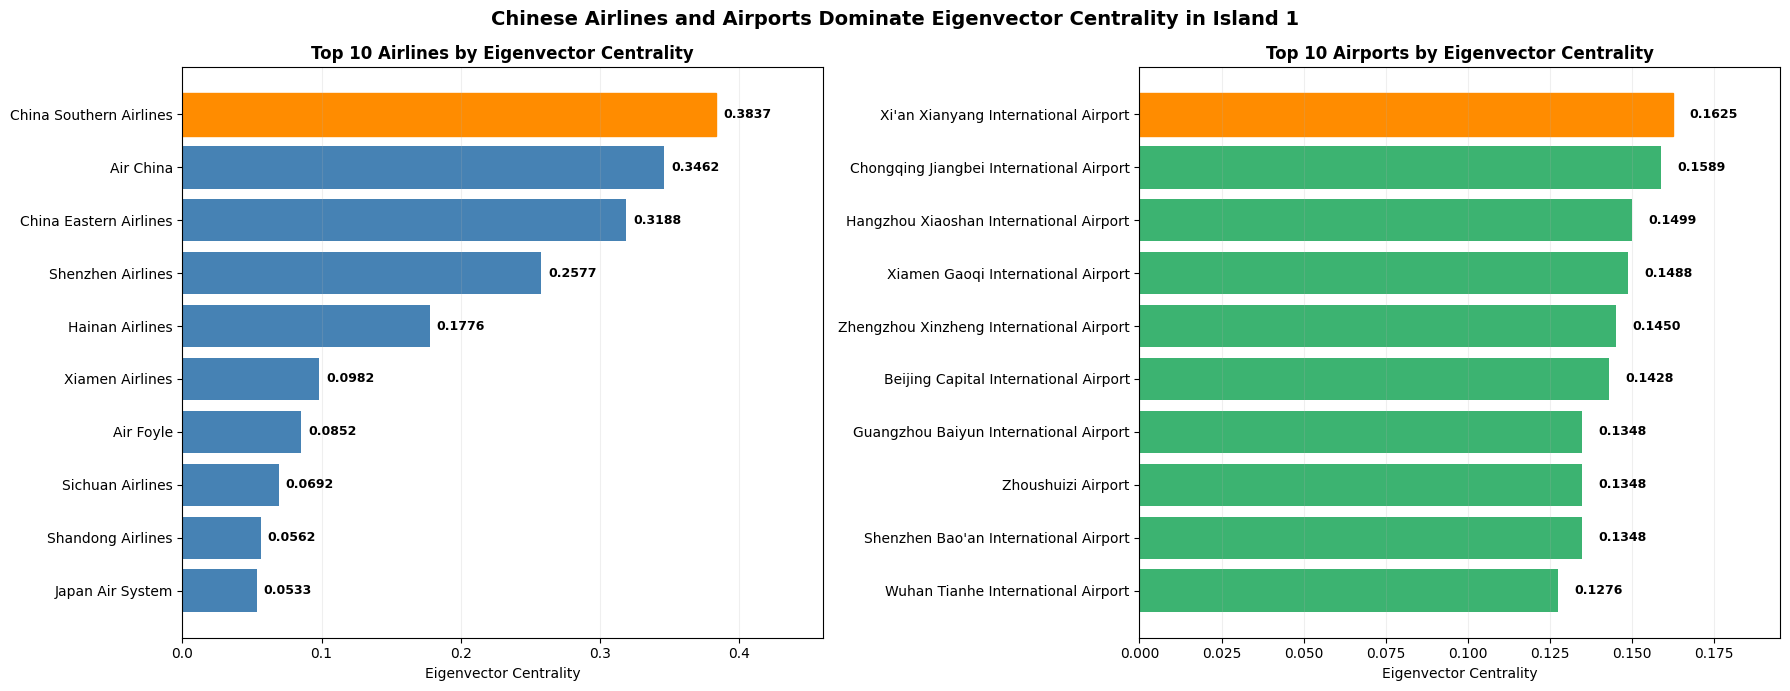

In [274]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, node_type, color in [
    (axes[0], 'Airline', 'steelblue'),
    (axes[1], 'Airport', 'mediumseagreen')
]:

    top = (
        eigenvector_df[eigenvector_df['Type'] == node_type]
        .sort_values('Eigenvector', ascending=False)
        .head(10)
        .sort_values('Eigenvector')
    )

    bars = ax.barh(
        top['Name'],
        top['Eigenvector'],
        color=color
    )

    # Highlight highest value
    bars[-1].set_color('darkorange')

    # Add value labels
    for bar in bars:
        value = bar.get_width()

        ax.text(
            value + 0.005,
            bar.get_y() + bar.get_height() / 2,
            f'{value:.4f}',
            va='center',
            fontsize=9,
            fontweight='bold'
        )

    ax.set_title(
        f'Top 10 {node_type}s by Eigenvector Centrality',
        fontweight='bold'
    )

    ax.set_xlabel('Eigenvector Centrality')
    ax.set_xlim(0, top['Eigenvector'].max() * 1.2)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle(
    'Chinese Airlines and Airports Dominate Eigenvector Centrality in Island 1',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Identify the Airlines and Airports in Island 2

In [276]:
# Select Island 2
island2_nodes = sorted_islands[1]

# Create the Island 2 graph
island2_graph = island_graph.subgraph(island2_nodes).copy()

# Separate airlines and airports
island2_airlines = [
    node for node in island2_graph.nodes()
    if node.startswith('airline_')
]

island2_airports = [
    node for node in island2_graph.nodes()
    if node.startswith('airport_')
]

# Display summary
print("ISLAND 2 SUMMARY")
print("Total nodes:", island2_graph.number_of_nodes())
print("Airlines:", len(island2_airlines))
print("Airports:", len(island2_airports))
print("Edges:", island2_graph.number_of_edges())

# Display airline names
print("\nAIRLINES IN ISLAND 2")

for node in sorted(island2_airlines):
    airline_id = int(node.replace('airline_', ''))
    print(airline_names.get(airline_id, node))

# Display airport names
print("\nAIRPORTS IN ISLAND 2")

for node in sorted(island2_airports):
    airport_id = int(node.replace('airport_', ''))
    print(airport_names.get(airport_id, node))

ISLAND 2 SUMMARY
Total nodes: 20
Airlines: 4
Airports: 16
Edges: 30

AIRLINES IN ISLAND 2
Azul
City Connexion Airlines
Oceanair
TAM Brazilian Airlines

AIRPORTS IN ISLAND 2
Val de Cans/Júlio Cezar Ribeiro International Airport
Pampulha - Carlos Drummond de Andrade Airport
Presidente Juscelino Kubistschek International Airport
Tancredo Neves International Airport
Afonso Pena Airport
Marechal Rondon Airport
Eduardo Gomes International Airport
Pinto Martins International Airport
Rio Galeão – Tom Jobim International Airport
Guarulhos - Governador André Franco Montoro International Airport
Viracopos International Airport
Salgado Filho Airport
Guararapes - Gilberto Freyre International Airport
Santos Dumont Airport
Congonhas Airport
Deputado Luiz Eduardo Magalhães International Airport


Island 2 Network Findings
- Island 2 contains 4 airlines and 16 airports, forming a relatively small regional network.

- The network is concentrated around Brazilian airlines and airports.
- Azul appears to connect to numerous airports, producing a star-like network structure.

- Several airports connect to only one airline within Island 2, while others are shared by multiple airlines.

- The Island Method isolates this group because its retained connections do not link to Island 1 at the selected threshold.

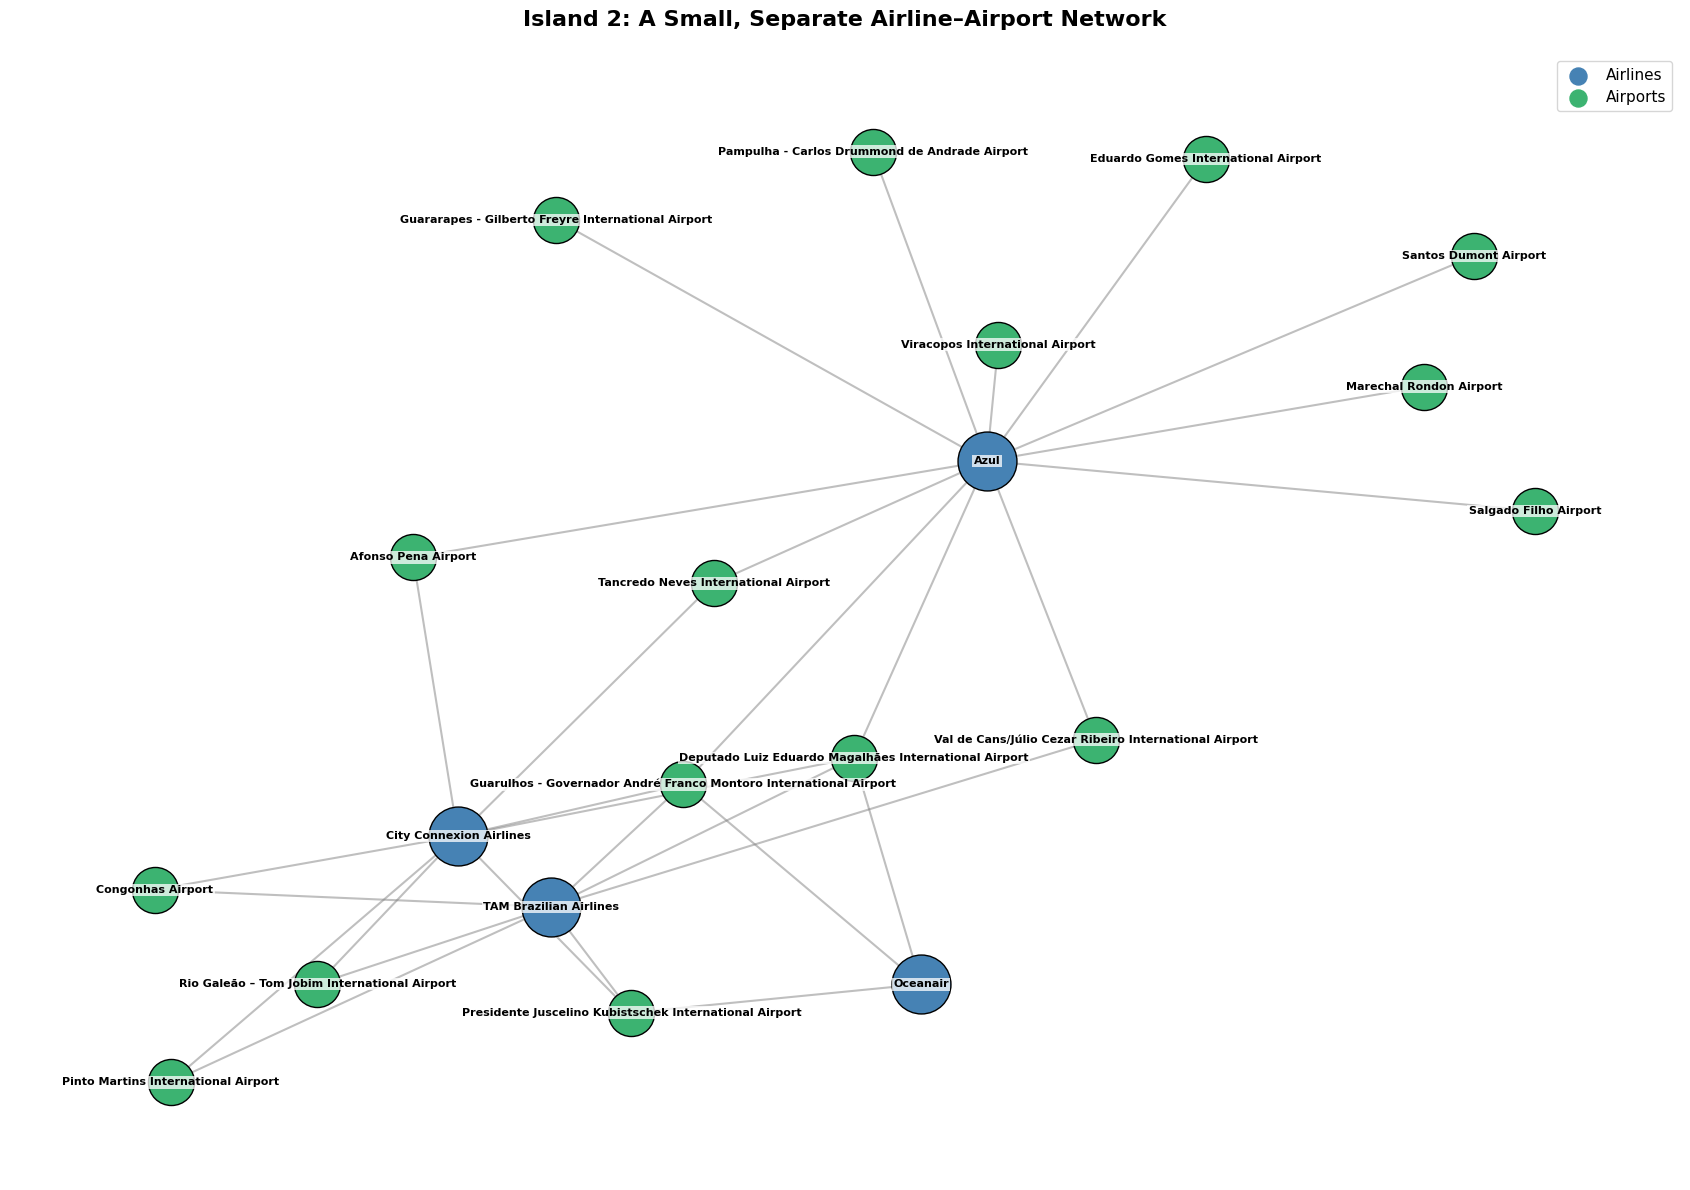

In [277]:
import networkx as nx
import matplotlib.pyplot as plt

# Create Island 2 graph
island2_graph = island_graph.subgraph(sorted_islands[1]).copy()

# Separate airline and airport nodes
airline_nodes_2 = [
    n for n in island2_graph.nodes()
    if n.startswith("airline_")
]

airport_nodes_2 = [
    n for n in island2_graph.nodes()
    if n.startswith("airport_")
]

# Create readable labels
labels = {}

for node in airline_nodes_2:
    airline_id = int(node.replace("airline_", ""))
    labels[node] = airline_names.get(airline_id, node)

for node in airport_nodes_2:
    airport_id = int(node.replace("airport_", ""))
    labels[node] = airport_names.get(airport_id, node)

# Create network layout
pos = nx.spring_layout(
    island2_graph,
    seed=42,
    k=1.3,
    iterations=200
)

plt.figure(figsize=(17, 12))

# Draw edges
nx.draw_networkx_edges(
    island2_graph,
    pos,
    edge_color="gray",
    alpha=0.5,
    width=1.5
)

# Draw airlines
nx.draw_networkx_nodes(
    island2_graph,
    pos,
    nodelist=airline_nodes_2,
    node_color="steelblue",
    node_size=1800,
    edgecolors="black"
)

# Draw airports
nx.draw_networkx_nodes(
    island2_graph,
    pos,
    nodelist=airport_nodes_2,
    node_color="mediumseagreen",
    node_size=1100,
    edgecolors="black"
)

# Add labels
nx.draw_networkx_labels(
    island2_graph,
    pos,
    labels=labels,
    font_size=8,
    font_weight="bold",
    bbox=dict(
        facecolor="white",
        alpha=0.75,
        edgecolor="none",
        pad=1
    )
)

# Legend
plt.scatter([], [], color="steelblue", s=150, label="Airlines")
plt.scatter([], [], color="mediumseagreen", s=150, label="Airports")

plt.legend(loc="upper right", fontsize=11)

plt.title(
    "Island 2: A Small, Separate Airline–Airport Network",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.axis("off")
plt.tight_layout()
plt.show()

# Degree Centrality for Airlines and Airports in Island 2

### Island 2 Degree Centrality Findings

- Azul has the highest airline degree (12), followed by City Connexion Airlines (8) and TAM Brazilian Airlines (7).

- Guarulhos International Airport and Deputado Luiz Eduardo Magalhães International Airport have the highest airport degree (4), connecting to all four airlines.

- The network is concentrated around Brazilian airlines and airports.
- Azul provides the broadest airport coverage, while the two highest-degree airports serve as shared connection points.

- **Key Finding:** Island 2 demonstrates how a small group of airlines can form a connected regional network through shared airports.

ISLAND 2: AIRLINE DEGREE CENTRALITY


,Name,Type,Degree,Degree Centrality
16,Azul,Airline,12,0.631579
8,City Connexion Airlines,Airline,8,0.421053
10,TAM Brazilian Airlines,Airline,7,0.368421
19,Oceanair,Airline,3,0.157895


ISLAND 2: AIRPORT DEGREE CENTRALITY


,Name,Type,Degree,Degree Centrality
3,Guarulhos - Governador André Franco Montoro In...,Airport,4,0.210526
9,Deputado Luiz Eduardo Magalhães International ...,Airport,4,0.210526
11,Presidente Juscelino Kubistschek International...,Airport,3,0.157895
1,Rio Galeão – Tom Jobim International Airport,Airport,2,0.105263
14,Val de Cans/Júlio Cezar Ribeiro International ...,Airport,2,0.105263
13,Congonhas Airport,Airport,2,0.105263
2,Afonso Pena Airport,Airport,2,0.105263
6,Tancredo Neves International Airport,Airport,2,0.105263
18,Pinto Martins International Airport,Airport,2,0.105263
5,Guararapes - Gilberto Freyre International Air...,Airport,1,0.052632


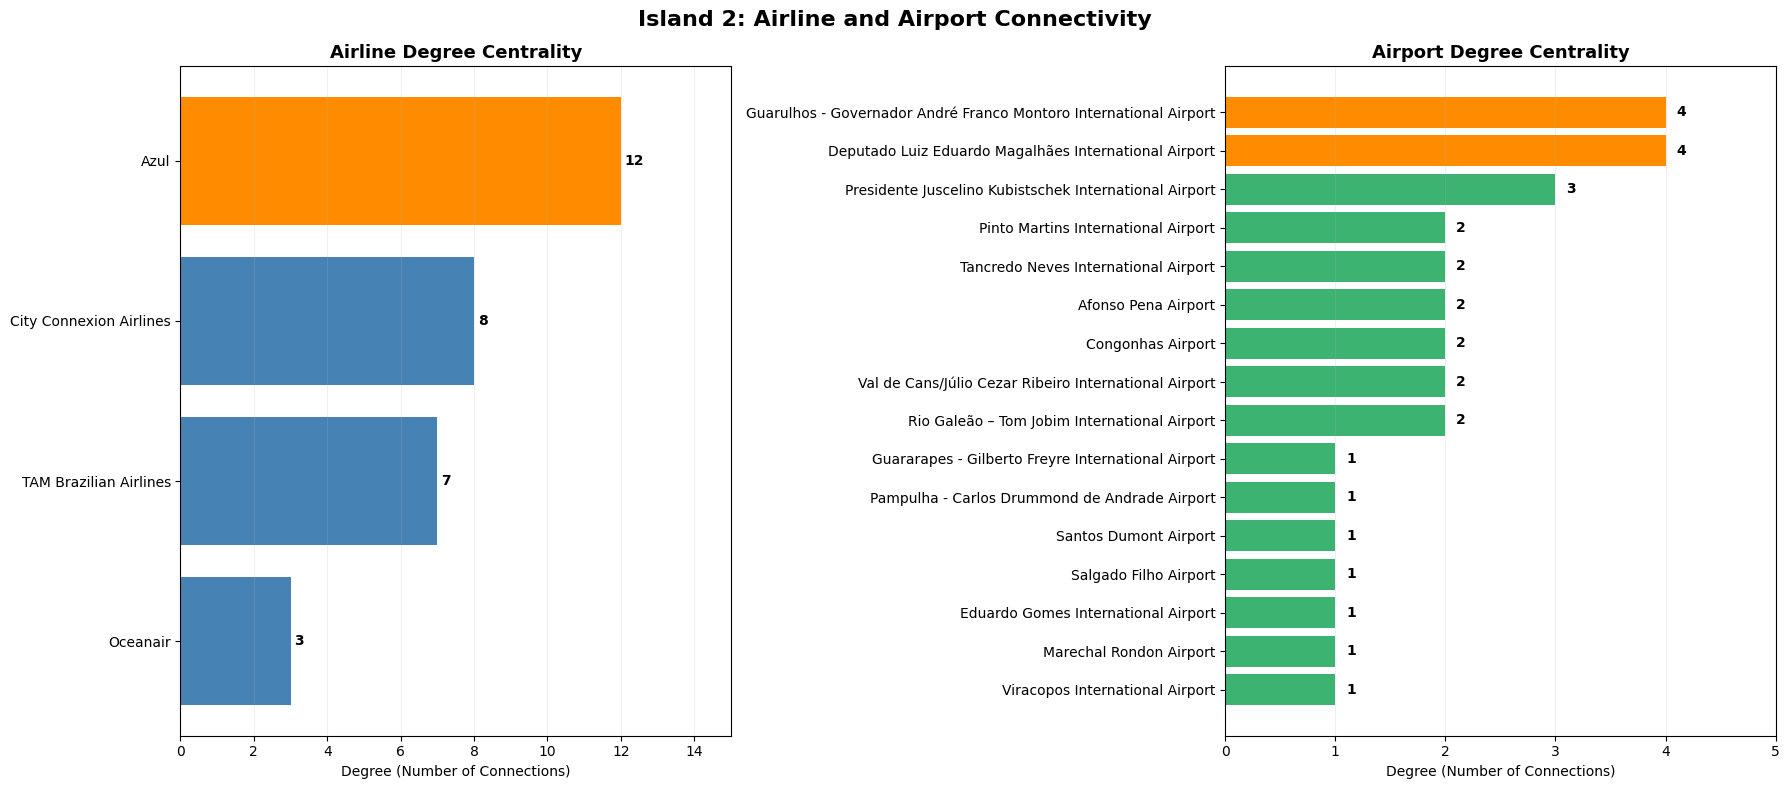

In [278]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Calculate degree centrality for Island 2
degree_centrality_2 = nx.degree_centrality(island2_graph)

# Step 2: Create results for airlines and airports
results = []

for node in island2_graph.nodes():

    node_id = int(node.split("_")[1])

    if node.startswith("airline_"):
        node_type = "Airline"
        name = airline_names.get(node_id, node)
    else:
        node_type = "Airport"
        name = airport_names.get(node_id, node)

    results.append({
        "Name": name,
        "Type": node_type,
        "Degree": island2_graph.degree(node),
        "Degree Centrality": degree_centrality_2[node]
    })

# Step 3: Create DataFrame
island2_centrality_df = pd.DataFrame(results)

# Separate airlines and airports
island2_airline_df = (
    island2_centrality_df[
        island2_centrality_df["Type"] == "Airline"
    ]
    .sort_values("Degree", ascending=False)
)

island2_airport_df = (
    island2_centrality_df[
        island2_centrality_df["Type"] == "Airport"
    ]
    .sort_values("Degree", ascending=False)
)

# Display tables
print("ISLAND 2: AIRLINE DEGREE CENTRALITY")
display(island2_airline_df)

print("ISLAND 2: AIRPORT DEGREE CENTRALITY")
display(island2_airport_df)


# Step 4: Create two charts
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, df, title, color in [
    (
        axes[0],
        island2_airline_df,
        "Airline Degree Centrality",
        "steelblue"
    ),
    (
        axes[1],
        island2_airport_df,
        "Airport Degree Centrality",
        "mediumseagreen"
    )
]:

    plot_df = df.sort_values("Degree")

    colors = [
        "darkorange" if d == plot_df["Degree"].max()
        else color
        for d in plot_df["Degree"]
    ]

    bars = ax.barh(
        plot_df["Name"],
        plot_df["Degree"],
        color=colors
    )

    # Add degree values
    for bar in bars:
        value = int(bar.get_width())

        ax.text(
            value + 0.1,
            bar.get_y() + bar.get_height() / 2,
            str(value),
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Degree (Number of Connections)")
    ax.set_xlim(0, plot_df["Degree"].max() * 1.25)
    ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    "Island 2: Airline and Airport Connectivity",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Betweenness Centrality for Airlines and Airports in Island 2

### Island 2 Betweenness Centrality Findings

- Azul has the highest airline betweenness centrality (0.6609), followed by City Connexion Airlines (0.2264) and TAM Brazilian Airlines (0.1612).

- Guarulhos International Airport and Deputado Luiz Eduardo Magalhães International Airport share the highest airport betweenness centrality (0.1279).

- Azul has both the highest degree and betweenness centrality, suggesting that it plays a dominant role in connecting different parts of Island 2.

- Several airports have zero betweenness, indicating that they do not serve as intermediate nodes on shortest paths.

- **Key Finding:** Island 2 depends heavily on Azul for network connectivity, while Guarulhos and Deputado Luiz Eduardo Magalhães act as important shared connection points.

ISLAND 2: AIRLINE BETWEENNESS CENTRALITY


,Name,Type,Betweenness
16,Azul,Airline,0.660916
8,City Connexion Airlines,Airline,0.226432
10,TAM Brazilian Airlines,Airline,0.161223
19,Oceanair,Airline,0.015757


ISLAND 2: AIRPORT BETWEENNESS CENTRALITY


,Name,Type,Betweenness
3,Guarulhos - Governador André Franco Montoro In...,Airport,0.127885
9,Deputado Luiz Eduardo Magalhães International ...,Airport,0.127885
14,Val de Cans/Júlio Cezar Ribeiro International ...,Airport,0.042142
2,Afonso Pena Airport,Airport,0.037529
6,Tancredo Neves International Airport,Airport,0.037529
11,Presidente Juscelino Kubistschek International...,Airport,0.016114
13,Congonhas Airport,Airport,0.002859
1,Rio Galeão – Tom Jobim International Airport,Airport,0.002859
18,Pinto Martins International Airport,Airport,0.002859
5,Guararapes - Gilberto Freyre International Air...,Airport,0.000000


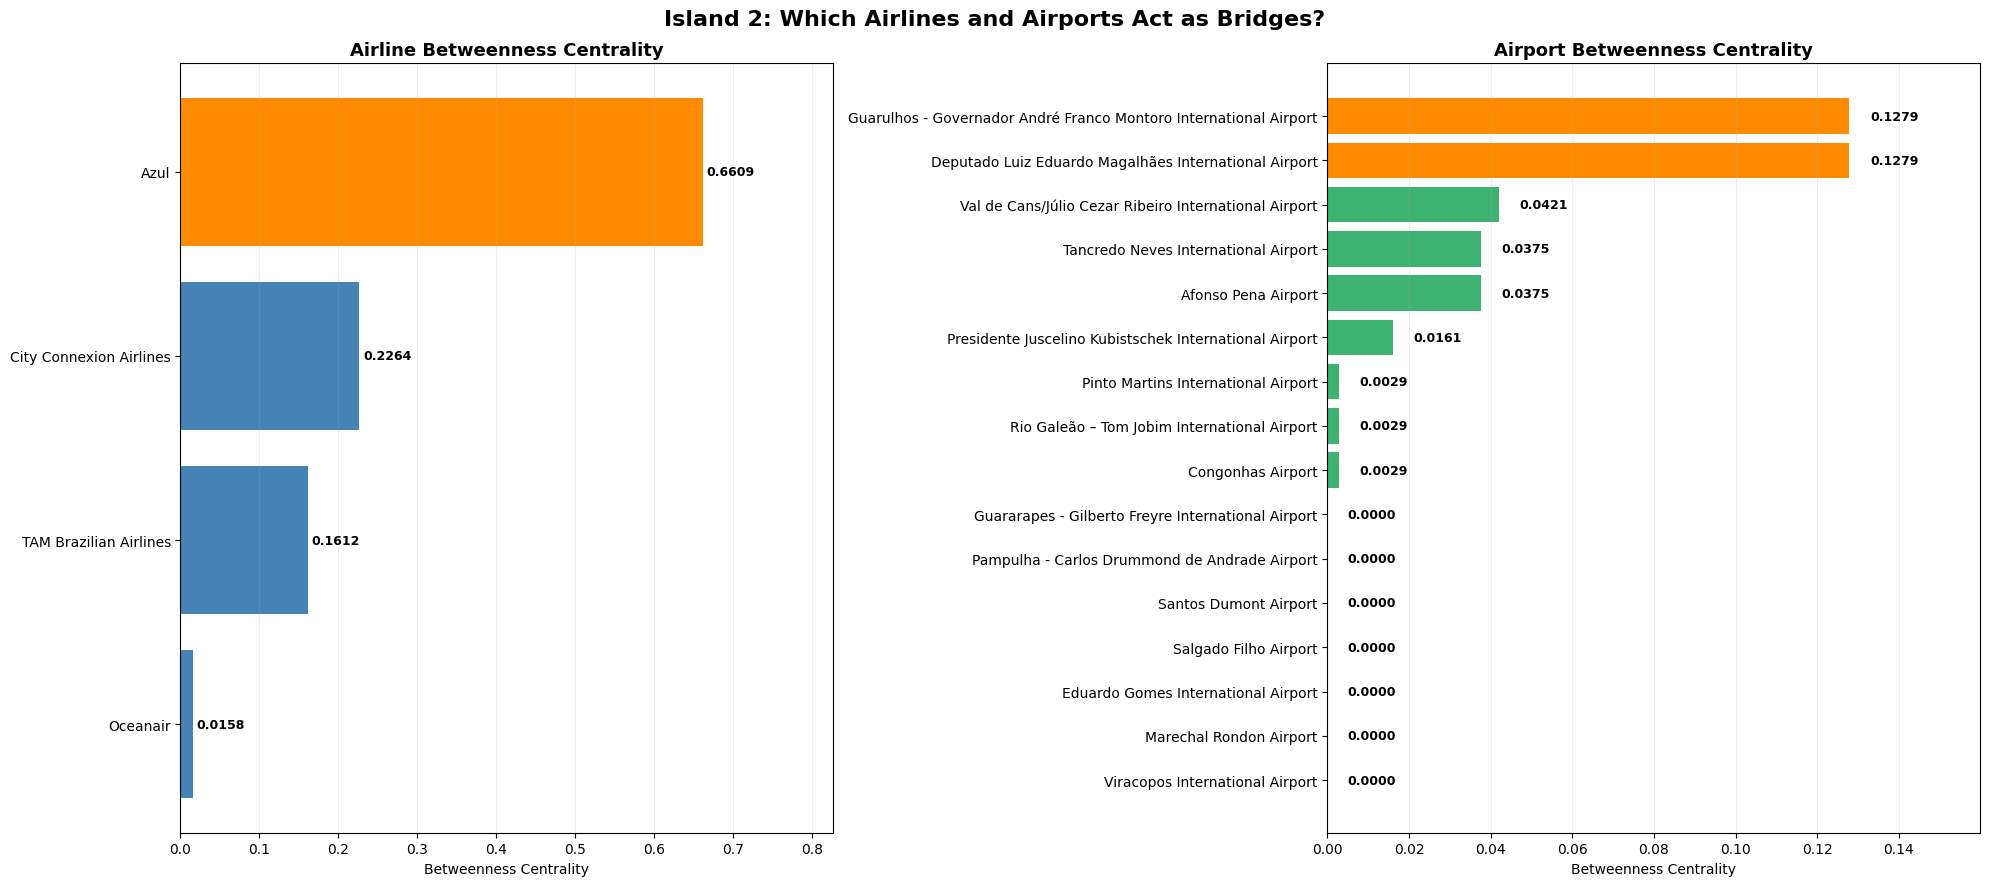

In [279]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Calculate betweenness centrality
betweenness_2 = nx.betweenness_centrality(
    island2_graph,
    normalized=True
)

# Step 2: Create a DataFrame for airlines and airports
results = []

for node, score in betweenness_2.items():

    node_id = int(node.split("_")[1])

    if node.startswith("airline_"):
        node_type = "Airline"
        name = airline_names.get(node_id, node)
    else:
        node_type = "Airport"
        name = airport_names.get(node_id, node)

    results.append({
        "Name": name,
        "Type": node_type,
        "Betweenness": score
    })

island2_betweenness_df = pd.DataFrame(results)

# Step 3: Separate airlines and airports
airline_betweenness_2 = (
    island2_betweenness_df[
        island2_betweenness_df["Type"] == "Airline"
    ]
    .sort_values("Betweenness", ascending=False)
)

airport_betweenness_2 = (
    island2_betweenness_df[
        island2_betweenness_df["Type"] == "Airport"
    ]
    .sort_values("Betweenness", ascending=False)
)

# Step 4: Display results
print("ISLAND 2: AIRLINE BETWEENNESS CENTRALITY")
display(airline_betweenness_2)

print("ISLAND 2: AIRPORT BETWEENNESS CENTRALITY")
display(airport_betweenness_2)


# Step 5: Create side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

for ax, df, title, color in [
    (
        axes[0],
        airline_betweenness_2,
        "Airline Betweenness Centrality",
        "steelblue"
    ),
    (
        axes[1],
        airport_betweenness_2,
        "Airport Betweenness Centrality",
        "mediumseagreen"
    )
]:

    plot_df = df.sort_values("Betweenness")

    colors = [
        "darkorange" if value == plot_df["Betweenness"].max()
        else color
        for value in plot_df["Betweenness"]
    ]

    bars = ax.barh(
        plot_df["Name"],
        plot_df["Betweenness"],
        color=colors
    )

    # Add values to bars
    for bar in bars:
        value = bar.get_width()

        ax.text(
            value + 0.005,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.4f}",
            va="center",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Betweenness Centrality")
    ax.set_xlim(0, max(plot_df["Betweenness"].max() * 1.25, 0.05))
    ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    "Island 2: Which Airlines and Airports Act as Bridges?",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Closeness Centrality for Airlines and Airports in Island 2

### Island 2 Closeness Centrality Findings

- Azul has the highest airline closeness centrality (0.6333), followed by City Connexion Airlines (0.5000).

- Guarulhos International Airport and Deputado Luiz Eduardo Magalhães International Airport share the highest airport closeness centrality (0.5588).

- Azul ranks highest in degree, betweenness, and closeness centrality, indicating its dominant structural position within Island 2.

- The same two airports also lead all three centrality measures.

- **Key Finding:** Island 2 has a concentrated network structure, with Azul and two major airports occupying the most central positions.

ISLAND 2: AIRLINE CLOSENESS CENTRALITY


,Name,Type,Closeness
16,Azul,Airline,0.633333
8,City Connexion Airlines,Airline,0.500000
10,TAM Brazilian Airlines,Airline,0.475000
19,Oceanair,Airline,0.395833


ISLAND 2: AIRPORT CLOSENESS CENTRALITY


,Name,Type,Closeness
3,Guarulhos - Governador André Franco Montoro In...,Airport,0.558824
9,Deputado Luiz Eduardo Magalhães International ...,Airport,0.558824
6,Tancredo Neves International Airport,Airport,0.500000
2,Afonso Pena Airport,Airport,0.500000
14,Val de Cans/Júlio Cezar Ribeiro International ...,Airport,0.500000
4,Santos Dumont Airport,Airport,0.395833
5,Guararapes - Gilberto Freyre International Air...,Airport,0.395833
0,Pampulha - Carlos Drummond de Andrade Airport,Airport,0.395833
17,Marechal Rondon Airport,Airport,0.395833
7,Viracopos International Airport,Airport,0.395833


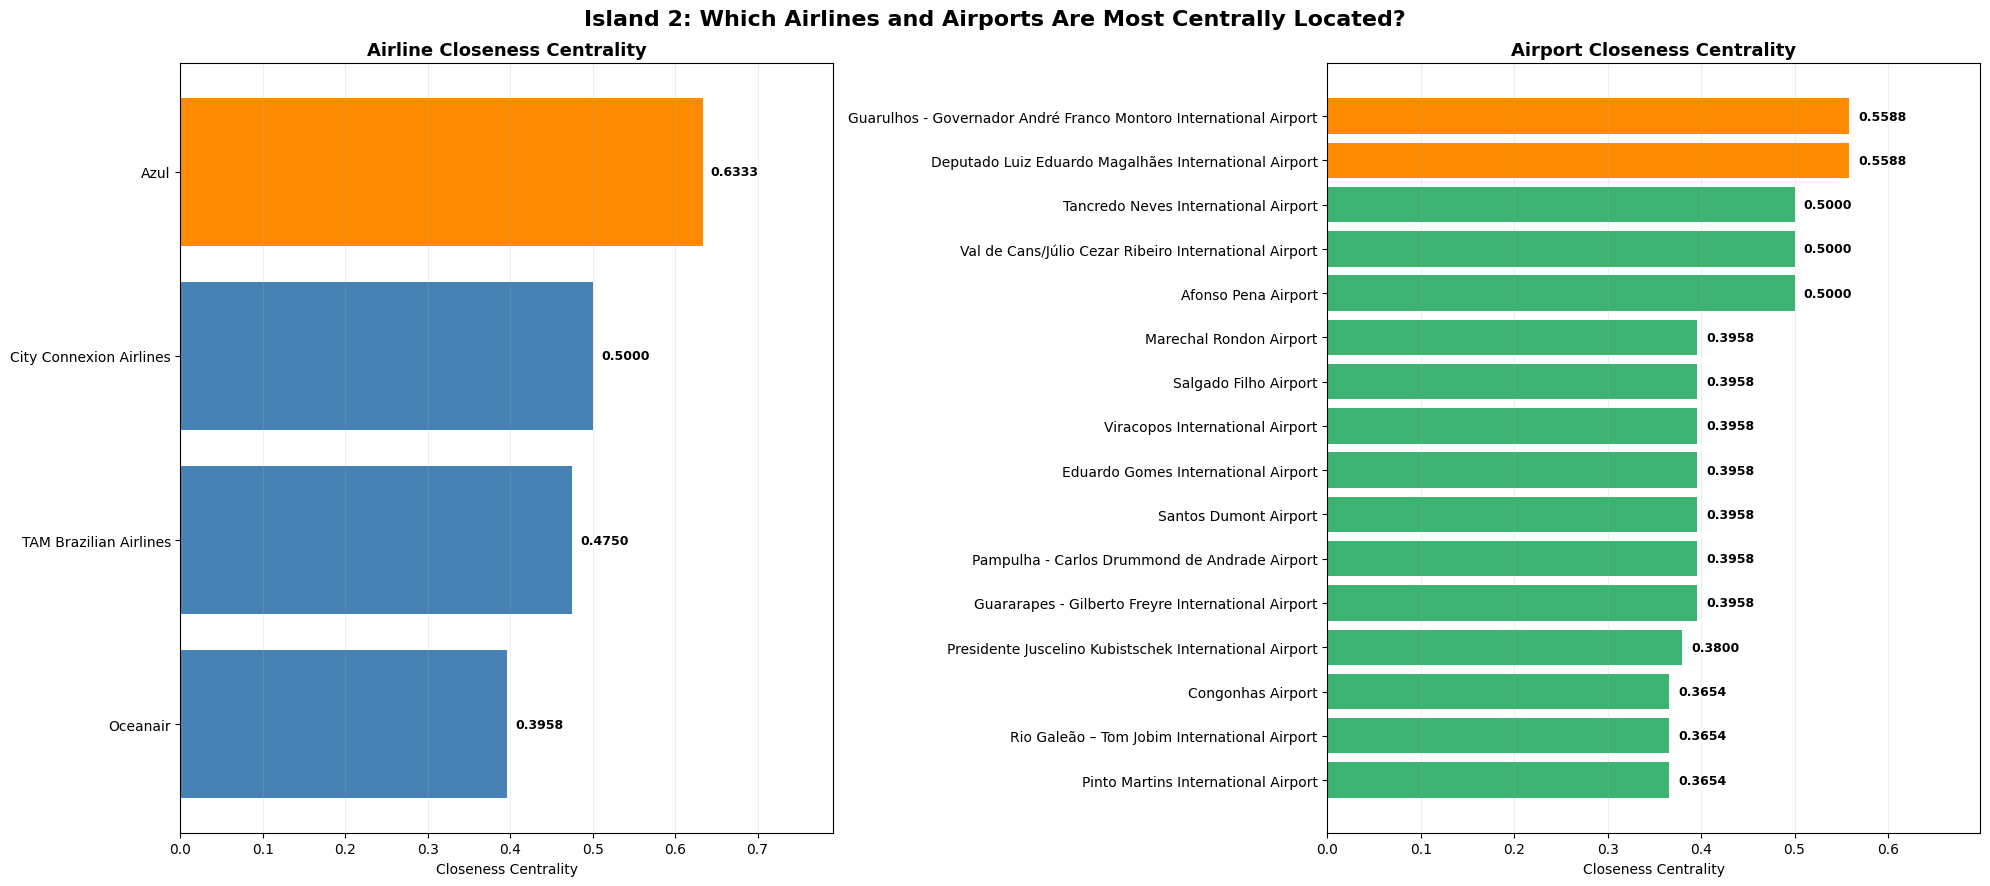

In [280]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Calculate closeness centrality
closeness_2 = nx.closeness_centrality(island2_graph)

# Step 2: Create results for airlines and airports
results = []

for node, score in closeness_2.items():

    node_id = int(node.split("_")[1])

    if node.startswith("airline_"):
        node_type = "Airline"
        name = airline_names.get(node_id, node)
    else:
        node_type = "Airport"
        name = airport_names.get(node_id, node)

    results.append({
        "Name": name,
        "Type": node_type,
        "Closeness": score
    })

# Step 3: Create DataFrame
island2_closeness_df = pd.DataFrame(results)

# Separate airlines and airports
airline_closeness_2 = (
    island2_closeness_df[
        island2_closeness_df["Type"] == "Airline"
    ]
    .sort_values("Closeness", ascending=False)
)

airport_closeness_2 = (
    island2_closeness_df[
        island2_closeness_df["Type"] == "Airport"
    ]
    .sort_values("Closeness", ascending=False)
)

# Display results
print("ISLAND 2: AIRLINE CLOSENESS CENTRALITY")
display(airline_closeness_2)

print("ISLAND 2: AIRPORT CLOSENESS CENTRALITY")
display(airport_closeness_2)


# Step 4: Create side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

for ax, df, title, color in [
    (
        axes[0],
        airline_closeness_2,
        "Airline Closeness Centrality",
        "steelblue"
    ),
    (
        axes[1],
        airport_closeness_2,
        "Airport Closeness Centrality",
        "mediumseagreen"
    )
]:

    plot_df = df.sort_values("Closeness")

    colors = [
        "darkorange" if value == plot_df["Closeness"].max()
        else color
        for value in plot_df["Closeness"]
    ]

    bars = ax.barh(
        plot_df["Name"],
        plot_df["Closeness"],
        color=colors
    )

    # Add values to bars
    for bar in bars:
        value = bar.get_width()

        ax.text(
            value + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.4f}",
            va="center",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Closeness Centrality")
    ax.set_xlim(0, max(plot_df["Closeness"].max() * 1.25, 0.1))
    ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    "Island 2: Which Airlines and Airports Are Most Centrally Located?",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Eigenvector Centrality for Airlines and Airports in Island 2

### Island 2: Eigenvector Centrality Findings

- Azul has the highest airline eigenvector centrality (0.4272), followed by City Connexion Airlines (0.3965) and TAM Brazilian Airlines (0.3509).

- Guarulhos International Airport and Deputado Luiz Eduardo Magalhães International Airport share the highest airport eigenvector centrality (0.3130).

- City Connexion Airlines has relatively high eigenvector centrality despite having fewer direct airport connections than Azul.

- All four centrality measures identify Azul as the leading airline and the same two airports as the most central.

- **Key Finding:** Island 2 has a concentrated network structure in which a small number of airlines and airports play prominent roles in connectivity and shortest-path relationships.

ISLAND 2: AIRLINE EIGENVECTOR CENTRALITY


,Name,Type,Eigenvector
16,Azul,Airline,0.427249
8,City Connexion Airlines,Airline,0.396495
10,TAM Brazilian Airlines,Airline,0.350929
19,Oceanair,Airline,0.192609


ISLAND 2: AIRPORT EIGENVECTOR CENTRALITY


,Name,Type,Eigenvector
3,Guarulhos - Governador André Franco Montoro In...,Airport,0.313035
9,Deputado Luiz Eduardo Magalhães International ...,Airport,0.313035
11,Presidente Juscelino Kubistschek International...,Airport,0.215217
2,Afonso Pena Airport,Airport,0.188594
6,Tancredo Neves International Airport,Airport,0.188594
14,Val de Cans/Júlio Cezar Ribeiro International ...,Airport,0.178162
13,Congonhas Airport,Airport,0.171120
1,Rio Galeão – Tom Jobim International Airport,Airport,0.171120
18,Pinto Martins International Airport,Airport,0.171120
5,Guararapes - Gilberto Freyre International Air...,Airport,0.097818


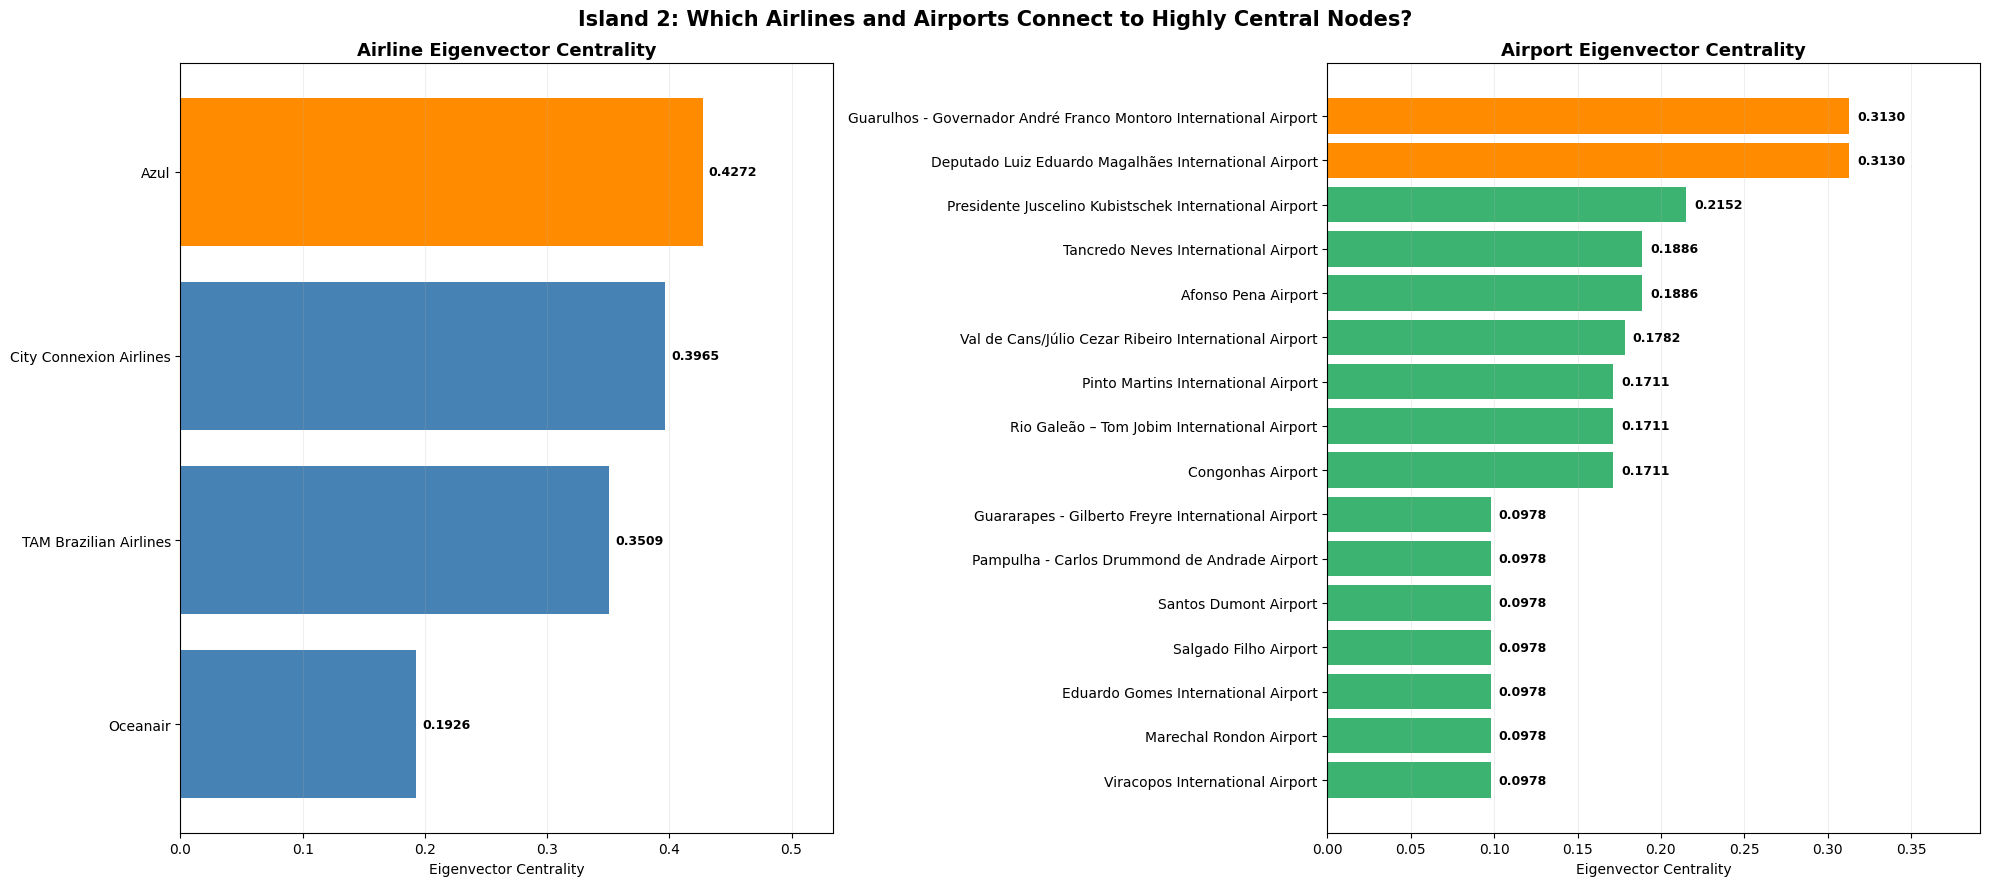

In [281]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Calculate eigenvector centrality
eigenvector_2 = nx.eigenvector_centrality(
    island2_graph,
    max_iter=5000,
    tol=1e-6
)

# Step 2: Create results for airlines and airports
results = []

for node, score in eigenvector_2.items():

    node_id = int(node.split("_")[1])

    if node.startswith("airline_"):
        node_type = "Airline"
        name = airline_names.get(node_id, node)
    else:
        node_type = "Airport"
        name = airport_names.get(node_id, node)

    results.append({
        "Name": name,
        "Type": node_type,
        "Eigenvector": score
    })

# Step 3: Create DataFrame
island2_eigenvector_df = pd.DataFrame(results)

# Separate airlines and airports
airline_eigenvector_2 = (
    island2_eigenvector_df[
        island2_eigenvector_df["Type"] == "Airline"
    ]
    .sort_values("Eigenvector", ascending=False)
)

airport_eigenvector_2 = (
    island2_eigenvector_df[
        island2_eigenvector_df["Type"] == "Airport"
    ]
    .sort_values("Eigenvector", ascending=False)
)

# Display tables
print("ISLAND 2: AIRLINE EIGENVECTOR CENTRALITY")
display(airline_eigenvector_2)

print("ISLAND 2: AIRPORT EIGENVECTOR CENTRALITY")
display(airport_eigenvector_2)


# Step 4: Create side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

for ax, df, title, color in [
    (
        axes[0],
        airline_eigenvector_2,
        "Airline Eigenvector Centrality",
        "steelblue"
    ),
    (
        axes[1],
        airport_eigenvector_2,
        "Airport Eigenvector Centrality",
        "mediumseagreen"
    )
]:

    plot_df = df.sort_values("Eigenvector")

    colors = [
        "darkorange" if value == plot_df["Eigenvector"].max()
        else color
        for value in plot_df["Eigenvector"]
    ]

    bars = ax.barh(
        plot_df["Name"],
        plot_df["Eigenvector"],
        color=colors
    )

    # Add value labels
    for bar in bars:
        value = bar.get_width()

        ax.text(
            value + 0.005,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.4f}",
            va="center",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Eigenvector Centrality")
    ax.set_xlim(
        0,
        max(plot_df["Eigenvector"].max() * 1.25, 0.05)
    )
    ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    "Island 2: Which Airlines and Airports Connect to Highly Central Nodes?",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Key Findings: Island 2
- Small regional network: Island 2 consists of 4 airlines and 16 airports, primarily concentrated in Brazil.

- Azul dominates the network: Azul has the highest degree (12), betweenness (0.6609), closeness (0.6333), and eigenvector centrality (0.4272).

- Two airports play central roles: Guarulhos International Airport and Deputado Luiz Eduardo Magalhães International Airport rank highest across all four airport centrality measures.

- Concentrated network structure: Unlike Island 1, where different airlines lead different centrality measures, Island 2 consistently identifies the same leading airline and airports.

- Island Method insight: The threshold of 10 reveals a distinct, geographically concentrated airline–airport network that is disconnected from Island 1 after filtering.

Overall Key Finding: Island 2 demonstrates how a small regional airline network can be structurally concentrated around one dominant airline (Azul) and two highly connected airports, highlighting the importance of these nodes in maintaining network connectivity.

# Compare Island 1 and Island 2 Using Network Statistics

In [282]:
import networkx as nx
import pandas as pd

# Function to calculate network statistics
def calculate_island_stats(G, island_name):

    airlines = [
        n for n in G.nodes()
        if n.startswith("airline_")
    ]

    airports = [
        n for n in G.nodes()
        if n.startswith("airport_")
    ]

    n_airlines = len(airlines)
    n_airports = len(airports)
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()

    # Bipartite density
    possible_edges = n_airlines * n_airports

    density = (
        n_edges / possible_edges
        if possible_edges > 0 else 0
    )

    # Average degree
    avg_degree = (
        2 * n_edges / n_nodes
        if n_nodes > 0 else 0
    )

    # Shortest paths and diameter
    if nx.is_connected(G):
        avg_path = nx.average_shortest_path_length(G)
        diameter = nx.diameter(G)
    else:
        avg_path = None
        diameter = None

    return {
        "Island": island_name,
        "Airlines": n_airlines,
        "Airports": n_airports,
        "Total Nodes": n_nodes,
        "Edges": n_edges,
        "Bipartite Density": round(density, 4),
        "Average Degree": round(avg_degree, 2),
        "Average Shortest Path": (
            round(avg_path, 2)
            if avg_path is not None else None
        ),
        "Diameter": diameter
    }


# Calculate statistics for both islands
island_comparison = pd.DataFrame([
    calculate_island_stats(largest_island_graph, "Island 1"),
    calculate_island_stats(island2_graph, "Island 2")
])

print("ISLAND 1 VS ISLAND 2: NETWORK STATISTICS")

display(island_comparison)

ISLAND 1 VS ISLAND 2: NETWORK STATISTICS


,Island,Airlines,Airports,Total Nodes,Edges,Bipartite Density,Average Degree,Average Shortest Path,Diameter
0,Island 1,177,362,539,1021,0.0159,3.79,6.24,17
1,Island 2,4,16,20,30,0.4688,3.00,2.32,4


# Island Method: Comparative Network Findings

The Island Method identified two distinct airline–airport network structures at an edge-weight threshold of 10.

Island 1 contains 539 nodes and 1,021 edges, forming a large but relatively sparse network with a bipartite density of 1.59%.

Its average shortest-path length of 6.24 and diameter of 17 indicate relatively long network distances.

In contrast, Island 2 contains 20 nodes and 30 edges, with a much higher bipartite density of 46.88%. Its average shortest-path length of 2.32 and diameter of 4 indicate a smaller, more compact network.

Centrality analysis further reveals that Island 1 has different leading airlines across centrality measures, whereas Azul consistently ranks highest across all four measures in Island 2.

Key Finding: The Island Method reveals that network size does not determine connectivity density. Island 1 is larger and structurally diverse, while Island 2 is smaller, denser, and more concentrated around a few central nodes.


One important qualification: Island 2's shorter paths are partly influenced by its much smaller size, so these differences should be interpreted as structural descriptions rather than evidence of better transportation efficiency.